# Data Understanding and Transformations: Creazione train e test alla fine

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [3]:
#df = pd.read_csv('df_understanding.csv')
df = pd.read_csv('df_understanding_analysis.csv')
# Per ora non rimuoviamo nessun anno così da avere un solo notebook, alla fine creeremo i diversi df

In [4]:
# columns_to_drop = ['longitude', 'latitude', 'growth_works', 'num_roles', 'roles_cleaned']
# df = df.drop(columns=columns_to_drop)

In [5]:
df

,nome_istituzione,city,regione,macroarea,type,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,roles,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,roles_cleaned,num_roles
0,Institute of Neurological Sciences,Mangone,Calabria,Sud,facility,117.0,960.0,94.0,2851.0,136.0,2447.0,152.0,6189.0,['institution'],50.0,35.0,29.0,28.0,20.0,13.0,22.0,12.0,14.0,24.0,11.0,14.0,20.0,10.0,7.0,74.81,22.22,1.48,1.48,73.04,21.74,4.35,0.87,70.37,19.75,8.64,1.23,63.27,29.59,4.08,3.06,65.71,23.81,5.71,4.76,['institution'],1
1,University of Siena,Siena,Tuscany,Centro,education,3034.0,21889.0,2844.0,40025.0,2662.0,53416.0,2719.0,75996.0,"['funder', 'institution']",394.0,63.0,52.0,400.0,77.0,69.0,398.0,102.0,75.0,438.0,151.0,142.0,349.0,93.0,62.0,45.11,17.44,14.16,23.30,43.66,17.15,16.17,23.02,44.97,17.19,13.95,23.89,42.75,16.65,15.60,25.01,45.32,15.95,15.75,22.97,"['funder', 'institution']",2
2,IRCCS Ospedale San Raffaele,Milan,Lombardy,Nord,healthcare,1629.0,16301.0,1426.0,34961.0,1270.0,38226.0,1163.0,49243.0,['institution'],280.0,90.0,123.0,376.0,130.0,186.0,385.0,141.0,139.0,425.0,210.0,181.0,313.0,126.0,98.0,82.78,13.71,2.00,1.50,79.04,17.56,1.42,1.98,73.76,21.86,2.36,2.03,75.72,19.89,2.48,1.92,72.41,23.45,1.57,2.57,['institution'],1
3,Bambino Gesù Children's Hospital,Rome,Lazio,Centro,healthcare,1627.0,14612.0,1804.0,31688.0,1686.0,39876.0,1542.0,55282.0,['institution'],232.0,28.0,25.0,231.0,28.0,27.0,244.0,59.0,41.0,209.0,32.0,24.0,215.0,46.0,38.0,66.37,28.78,2.15,2.70,65.48,28.03,4.12,2.37,66.84,27.35,3.90,1.92,69.99,25.60,2.28,2.13,69.21,25.67,2.96,2.16,['institution'],1
4,University of Florence,Florence,Tuscany,Centro,education,7698.0,66448.0,7750.0,100752.0,7537.0,131602.0,7306.0,173527.0,"['funder', 'institution', 'publisher']",1141.0,219.0,177.0,1098.0,189.0,176.0,1083.0,205.0,174.0,1043.0,210.0,165.0,949.0,222.0,116.0,32.44,17.50,15.44,34.62,31.94,17.75,15.81,34.51,32.98,16.92,16.39,33.72,33.15,15.82,16.33,34.70,31.83,14.80,17.52,35.85,"['funder', 'institution', 'publisher']",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
953,Cereal Research Centre,Foggia,Apulia,Sud,facility,372.0,2907.0,326.0,4800.0,329.0,6916.0,325.0,11865.0,['institution'],82.0,18.0,18.0,80.0,25.0,16.0,72.0,24.0,17.0,69.0,16.0,21.0,66.0,26.0,13.0,15.60,61.35,2.13,20.92,12.36,68.16,2.62,16.85,14.24,59.72,3.82,22.22,13.48,61.13,3.45,21.94,8.90,64.77,2.49,23.84,['institution'],1
954,Ospedale Pediatrico Giovanni XXIII,Bari,Apulia,Sud,healthcare,167.0,1308.0,182.0,1749.0,152.0,2241.0,145.0,4627.0,['institution'],21.0,10.0,13.0,24.0,10.0,13.0,18.0,1.0,4.0,29.0,13.0,12.0,26.0,16.0,10.0,75.86,18.97,2.59,2.59,80.33,13.93,3.28,2.46,74.36,21.79,2.56,1.28,77.54,19.57,1.45,1.45,77.54,16.67,2.90,2.90,['institution'],1
955,Ospedale San Bortolo,Vicenza,Veneto,Nord,healthcare,328.0,3031.0,312.0,2998.0,280.0,4931.0,280.0,7011.0,['institution'],30.0,4.0,2.0,32.0,6.0,6.0,33.0,12.0,7.0,27.0,7.0,6.0,31.0,15.0,11.0,85.17,10.27,1.90,2.66,88.55,7.25,1.53,2.67,87.81,10.04,1.08,1.08,83.84,10.44,1.35,4.38,84.62,9.79,2.1

## Ora che non ci sono nan, analisi bivariate

<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1382/858245799.py:20: SyntaxWarning: invalid escape sequence '\d'
  df_long['year'] = df_long['year'].str.extract('(\d+)').astype(int)


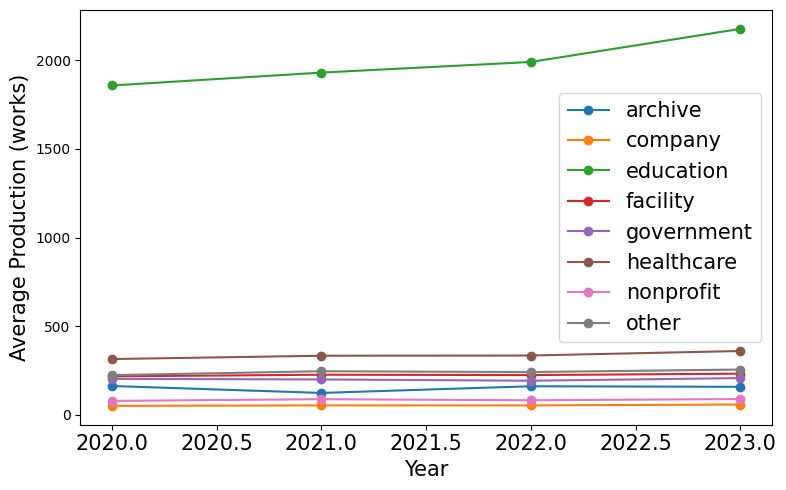

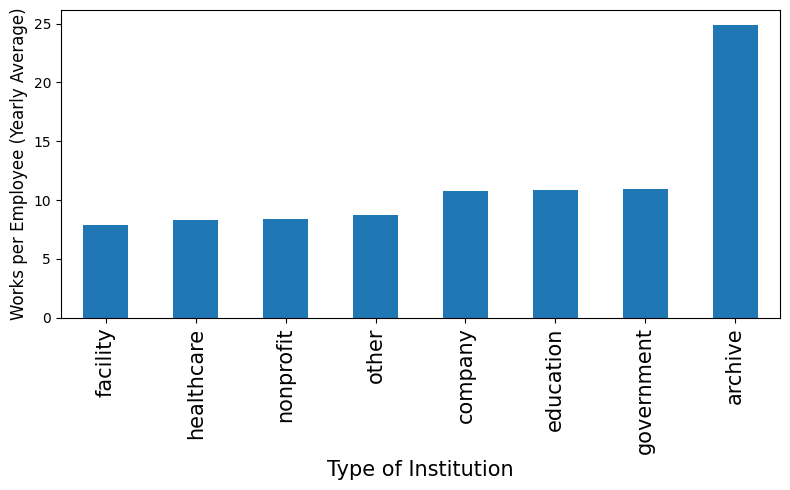

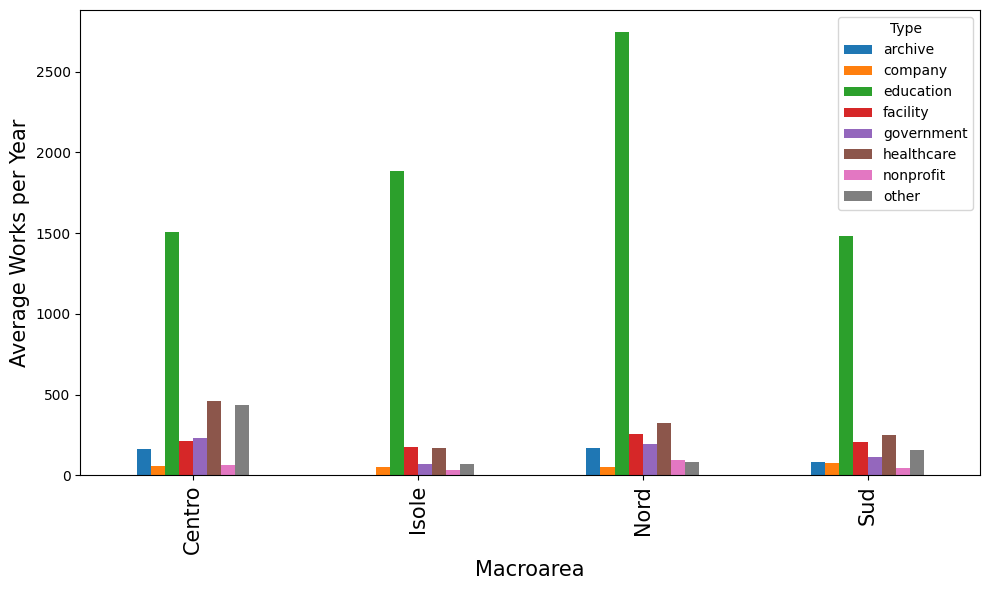

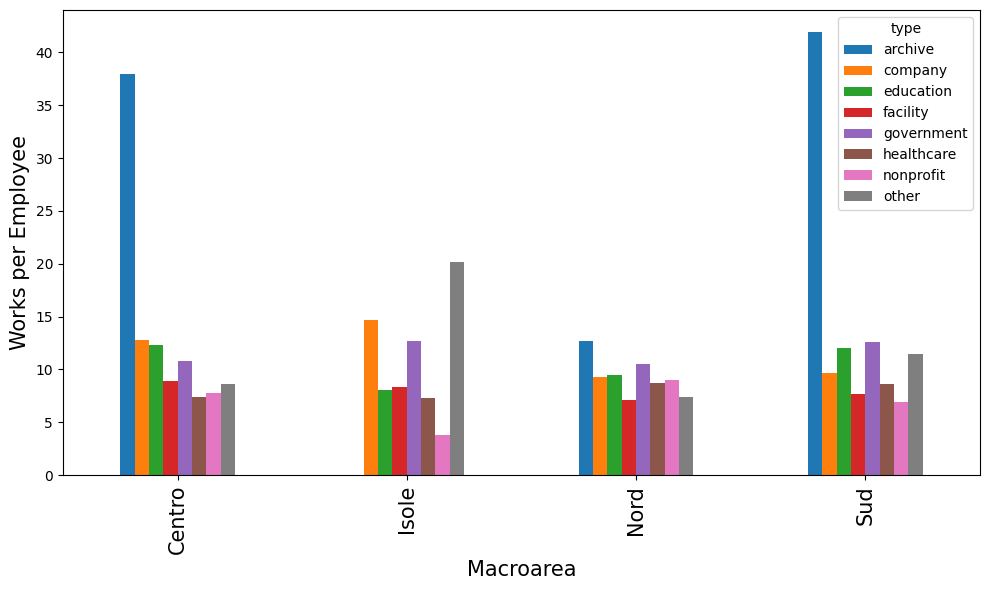

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1️⃣ Trend temporale 2020-2023
# =========================
years = [2020, 2021, 2022, 2023]

# Trasformazione in formato long per i works_count
df_long = pd.melt(
    df,
    id_vars=['type'],
    value_vars=[f'works_count_{y}' for y in years],
    var_name='year',
    value_name='works'
)

# Pulizia anno
df_long['year'] = df_long['year'].str.extract('(\d+)').astype(int)

# Trend medio per tipo
trend = df_long.groupby(['year', 'type'])['works'].mean().reset_index()

# Grafico trend
plt.figure(figsize=(8,5))
for t in trend['type'].unique():
    subset = trend[trend['type'] == t]
    plt.plot(subset['year'], subset['works'], marker='o', label=t)

plt.xlabel("Year", fontsize = 15)
plt.ylabel("Average Production (works)", fontsize = 15)
plt.xticks(fontsize = 15)
plt.legend(fontsize = 15)
plt.tight_layout()
plt.show()

# Crescita 2020-2023
# df['growth_works'] = df['works_count_2023'] - df['works_count_2020']
# df.groupby('type')['growth_works'].mean().sort_values().plot(kind='bar', figsize=(8,5))
# plt.ylabel("Average Growth in Works")
# plt.title("Average Growth per Type (2020-2023)")
# plt.tight_layout()
# plt.show()


# =========================
# 2️⃣ Produttività per dipendente (efficienza) 2020-2023
# =========================
# Calcolo produttività per ogni anno
for y in years:
    df[f'prod_per_staff_{y}'] = df[f'works_count_{y}'] / df[f'tot_dipendenti_per_anno_{y}']

# Media produttività su tutti gli anni
df['prod_per_staff_mean'] = df[[f'prod_per_staff_{y}' for y in years]].mean(axis=1)

# Grafico a barre efficienza media per tipo
eff = df.groupby('type')['prod_per_staff_mean'].mean().sort_values()
eff.plot(kind='bar', figsize=(8,5))
plt.ylabel("Works per Employee (Yearly Average)", fontsize = 12)
plt.xlabel("Type of Institution", fontsize = 15)
plt.xticks(fontsize = 15)
plt.tight_layout()
plt.show()

# Istogramma distribuzione efficienza per tipo
# plt.figure(figsize=(10,6))
# for t in df['type'].unique():
#     subset = df[df['type'] == t]
#     plt.hist(subset['prod_per_staff_mean'], bins=15, alpha=0.5, label=t)

# plt.legend(title="Type")
# plt.xlabel("Works per Employee (Yearly Average)")
# plt.ylabel("Frequency")
# plt.title("Distribution of Productivity per Employee by Type (2020-2023)")
# plt.tight_layout()
# plt.show()


# =========================
# 3️⃣ Analisi geografica 2020-2023
# =========================
# Media works per istituzione su tutti gli anni
df['works_mean_all_years'] = df[[f'works_count_{y}' for y in years]].mean(axis=1)

# Media per macroarea e tipo
geo = df.groupby(['macroarea', 'type'])['works_mean_all_years'].mean().unstack()

# Grafico a barre
geo.plot(kind='bar', figsize=(10,6))
plt.ylabel("Average Works per Year", fontsize = 15)
plt.xlabel("Macroarea", fontsize = 15)
plt.xticks(fontsize = 15)
plt.legend(title="Type", fontsize = 10)
plt.tight_layout()
plt.show()

# Heatmap
# plt.figure(figsize=(10,6))
# plt.imshow(geo, aspect='auto', cmap='viridis')
# plt.xticks(range(len(geo.columns)), geo.columns, rotation=45)
# plt.yticks(range(len(geo.index)), geo.index)
# plt.colorbar(label='Average Works per Year')
# plt.title("Heatmap of Average Production (Macroarea vs Type, 2020-2023)")
# plt.tight_layout()
# plt.show()

# Efficienza geografica (prod_per_staff_mean)
geo_eff = df.groupby(['macroarea', 'type'])['prod_per_staff_mean'].mean().unstack()
geo_eff.plot(kind='bar', figsize=(10,6))
plt.ylabel("Works per Employee", fontsize = 15)
plt.xlabel("Macroarea", fontsize = 15)
plt.xticks(fontsize = 15)
plt.tight_layout()
plt.show()

Per la classificazione, abbiamo bisogno di:
- Dataset di training con features fino al 2023 e target il flow predetto per il 2024
- Dataset di test con features fino al 2024 e target il flow predetto fino al 2024

Quindi, creiamo la feature out_in_flow_2023_2024 per capire come si situavano le istituzioni alla fine del 2024 che sarà il nostro target-> dopo divisione train/test per evitare data leakage

In [102]:
def analyze_columns(dataframe, list_of_cols):
    for i in list_of_cols: 

        subject = dataframe[i]
        print(f"Value counts for {i}: {len(subject.value_counts())}")

        sns.histplot(subject)
        plt.title(f"Distribution {i}")
        plt.xlabel("Number of papers")
        plt.ylabel("Istituzioni")
        plt.show()

In [103]:
def log_transform_works(dataframe, list_of_cols):
    for i in list_of_cols:
        dataframe[i] = np.log1p(dataframe[i])

        sns.histplot(dataframe[i])
        plt.title(f"Distribution post log transform {i}")
        plt.xlabel("Number of papers")
        plt.ylabel("Number of institutions")
        plt.show()


In [104]:
def log_transform_personnel(dataframe, list_of_cols):
    for i in list_of_cols:
        dataframe[i] = np.log1p(dataframe[i])

        sns.histplot(dataframe[i])
        plt.title(f"Distribution post log transform {i}")
        plt.xlabel("Number of papers")
        plt.ylabel("Number of institutions")
        plt.show()

#### works_count

In [105]:
works_cols = df.filter(regex=r"^works_count_\d{4}$").columns.tolist()

Value counts for works_count_2023: 442


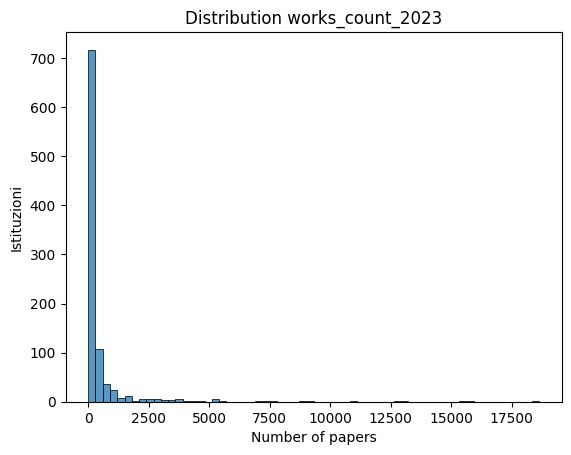

Value counts for works_count_2022: 438


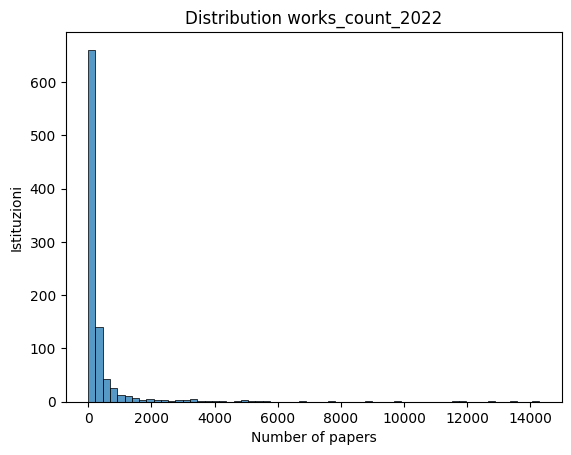

Value counts for works_count_2021: 443


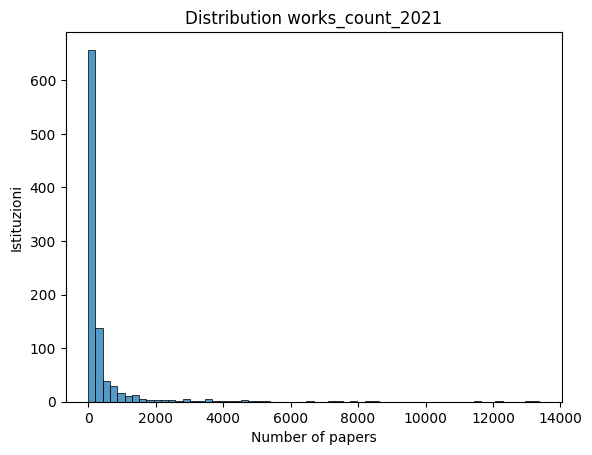

Value counts for works_count_2020: 433


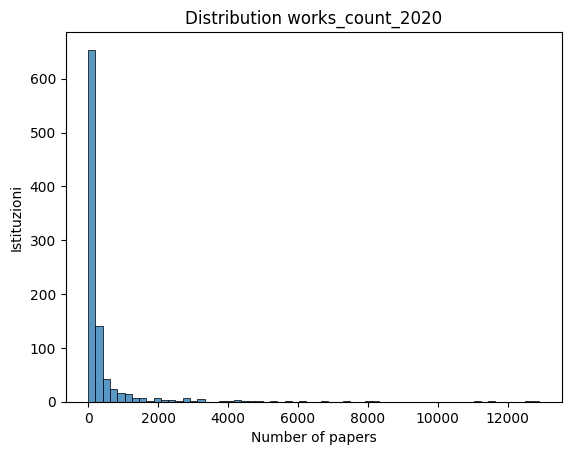

In [106]:
analyze_columns(df, works_cols)
# Fortemente skewed, applichiamo trasformazione logaritmica

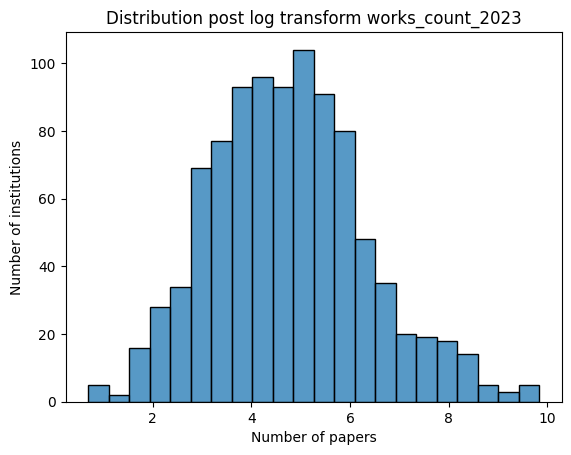

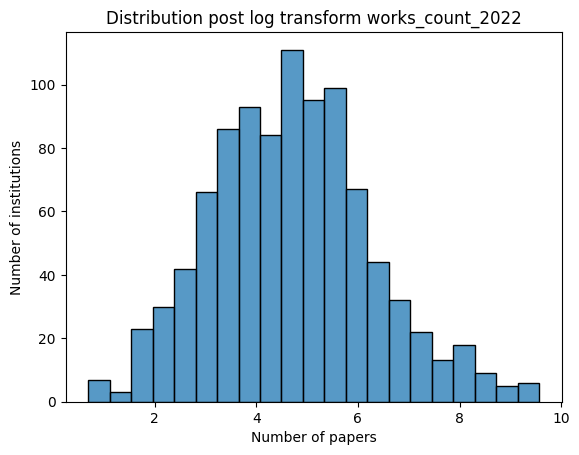

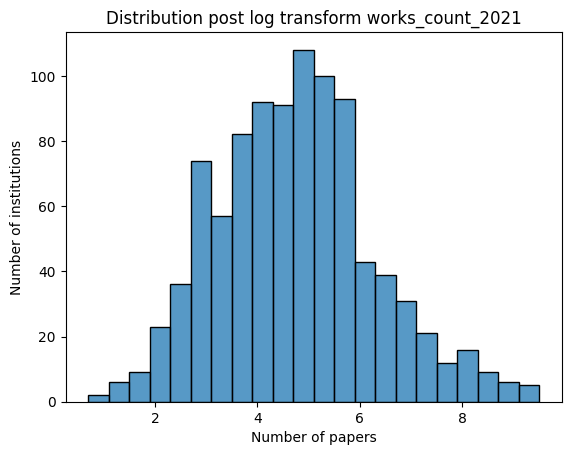

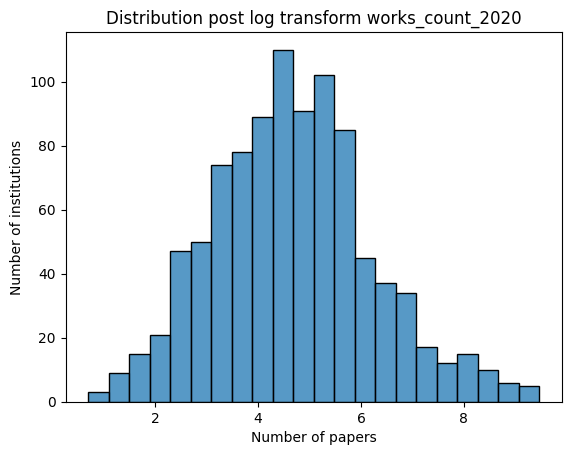

In [107]:
log_transform_works(df, works_cols)

#### cited_by_count

In [108]:
cited_cols = df.filter(regex=r"^cited_by_count_\d{4}$").columns.tolist()

Value counts for cited_by_count_2023: 792


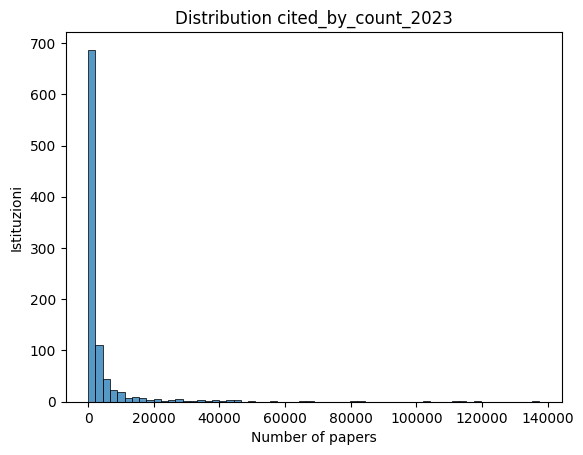

Value counts for cited_by_count_2022: 851


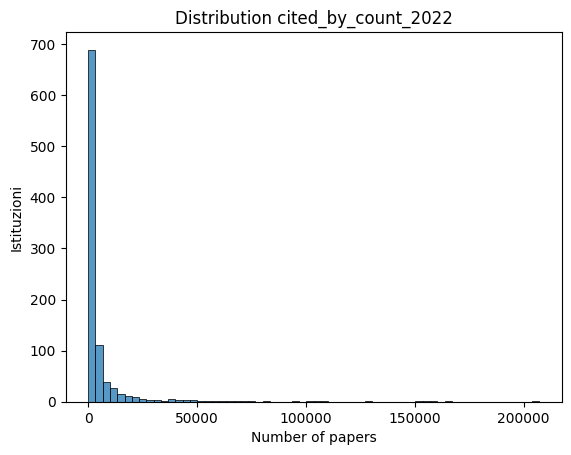

Value counts for cited_by_count_2021: 875


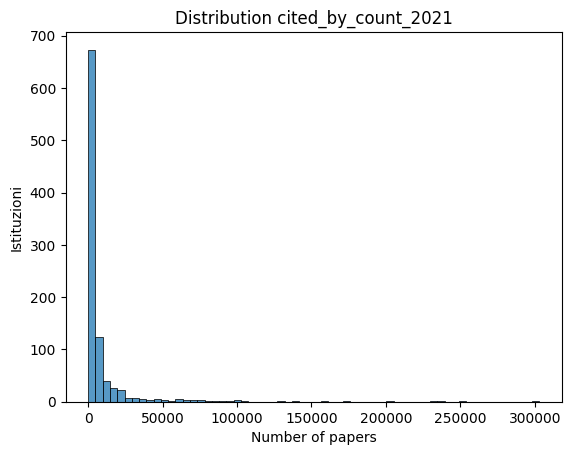

Value counts for cited_by_count_2020: 891


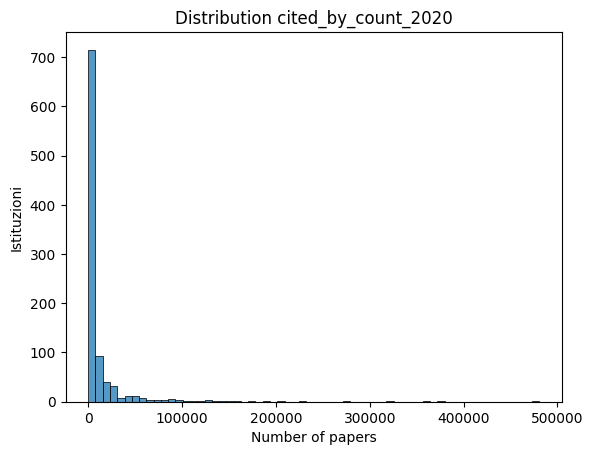

In [109]:
analyze_columns(df, cited_cols)

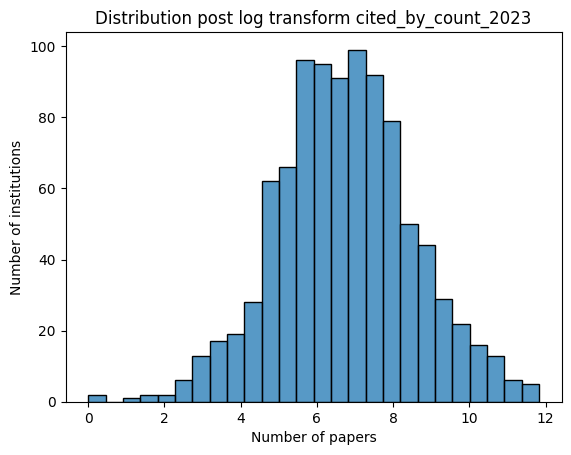

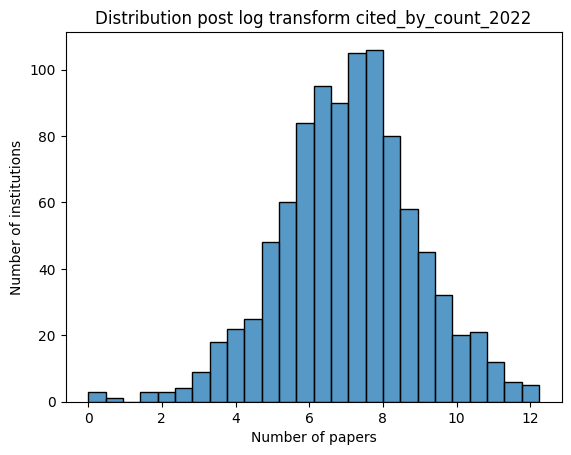

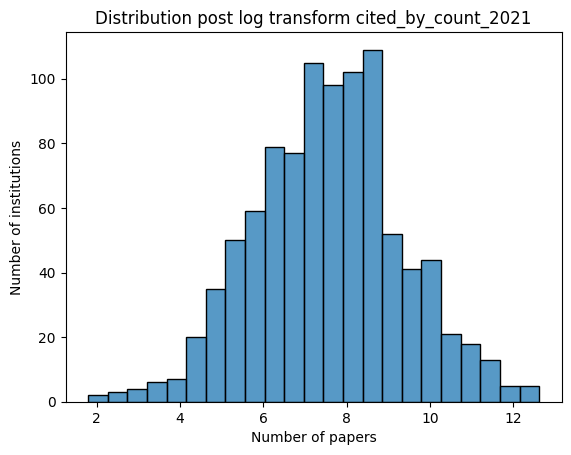

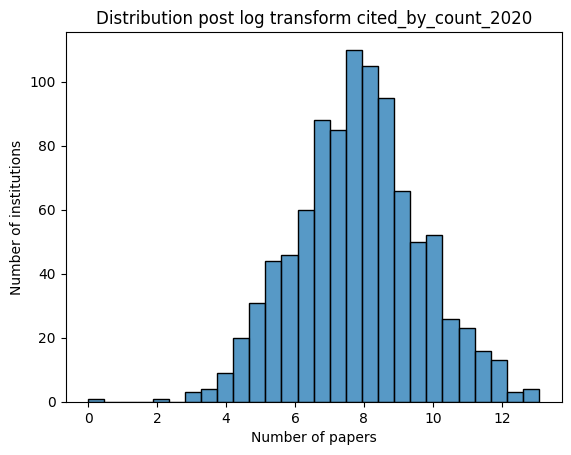

In [110]:
log_transform_works(df, cited_cols)

### Personale

In [111]:
columns_tot_dipendenti = []
columns_entries = []
columns_leaving = []

colonne = df.columns
for i in colonne:
    if 'dipendenti' in i:
        columns_tot_dipendenti.append(i)

    elif 'studiosi_entrati' in i:
        columns_entries.append(i)

    elif 'studiosi_usciti' in i:
        columns_leaving.append(i)

#### tot_dipendenti

Value counts for tot_dipendenti_per_anno_2020: 195


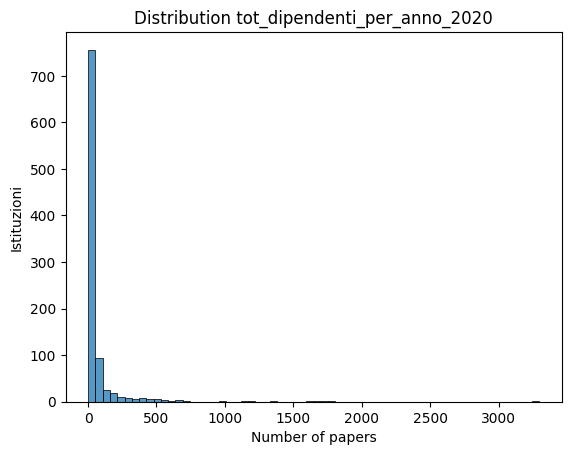

Value counts for tot_dipendenti_per_anno_2021: 202


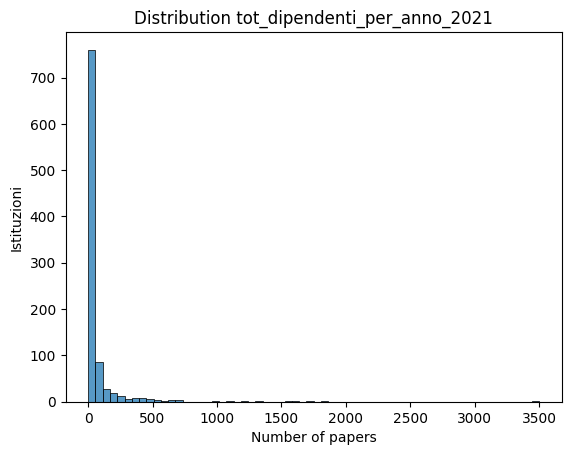

Value counts for tot_dipendenti_per_anno_2022: 200


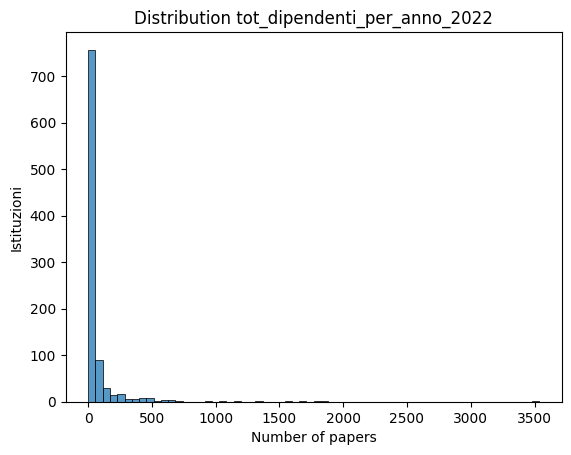

Value counts for tot_dipendenti_per_anno_2023: 189


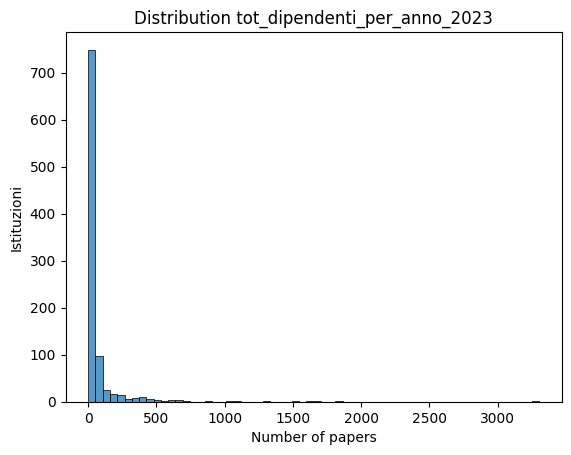

Value counts for tot_dipendenti_per_anno_2024: 187


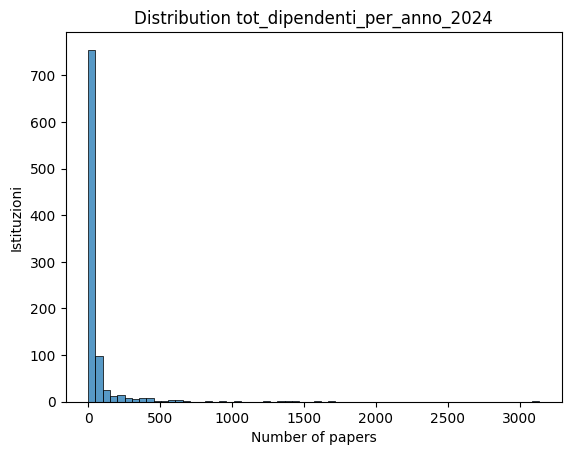

In [112]:
analyze_columns(df, columns_tot_dipendenti)

In [113]:
(df[columns_tot_dipendenti] == 0).any().any()

np.False_

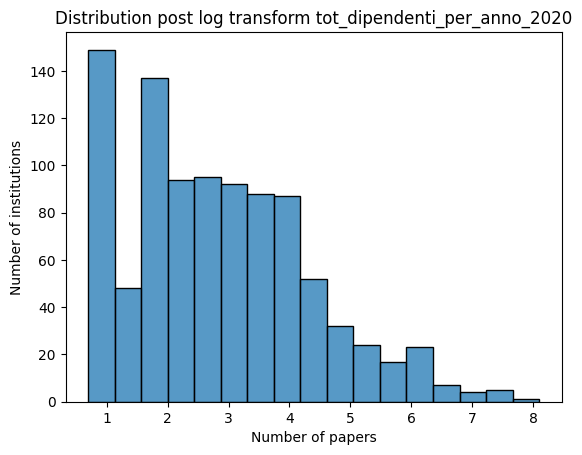

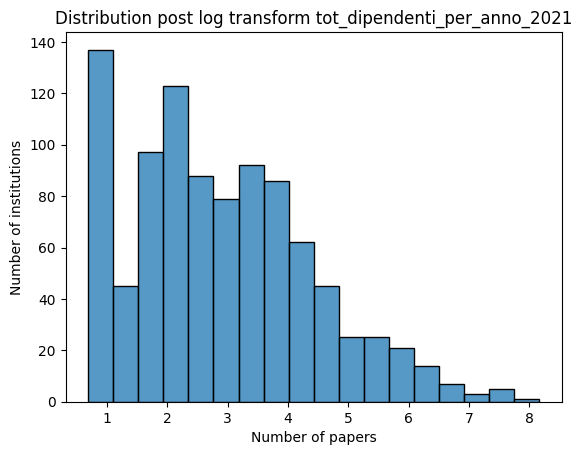

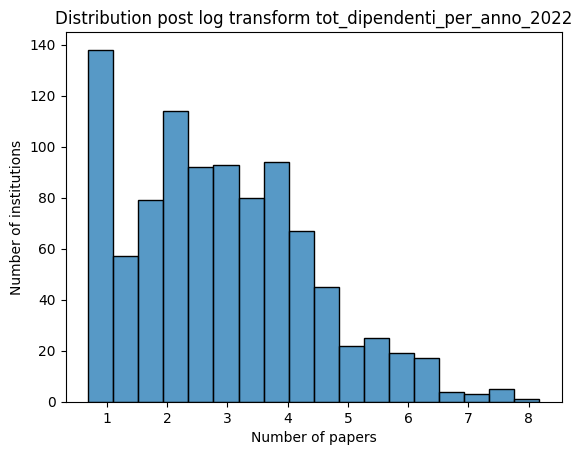

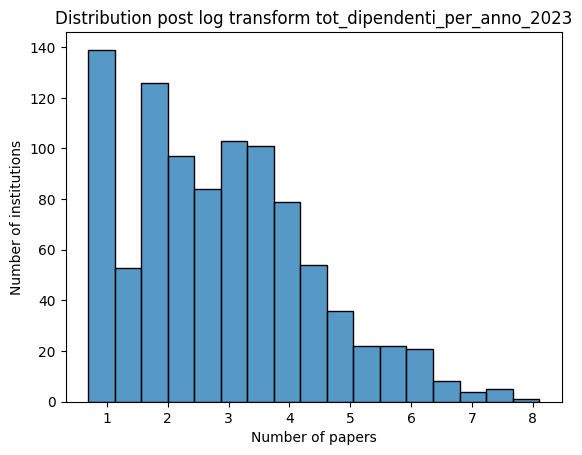

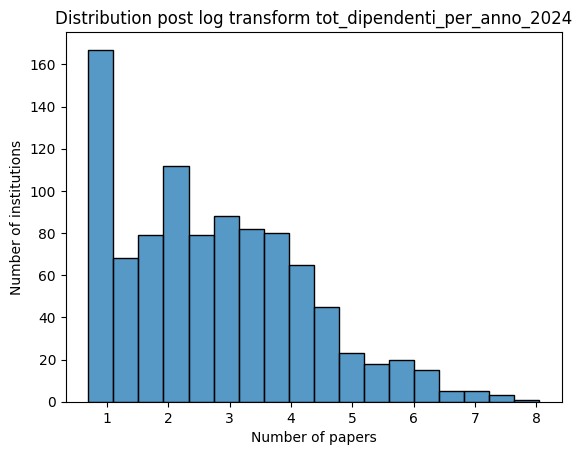

In [114]:
log_transform_personnel(df, columns_tot_dipendenti)

#### studiosi_entrati

Value counts for studiosi_entrati_2020: 91


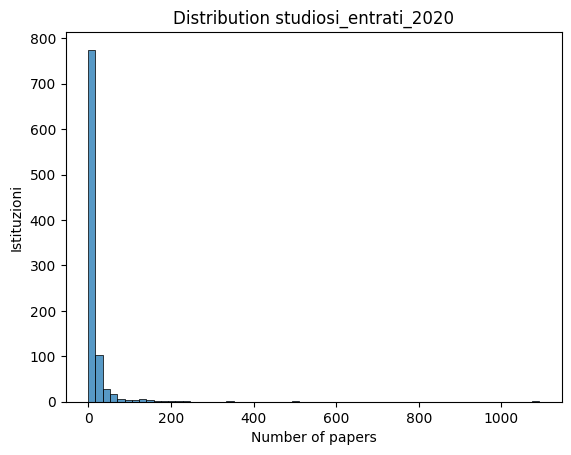

Value counts for studiosi_entrati_2021: 107


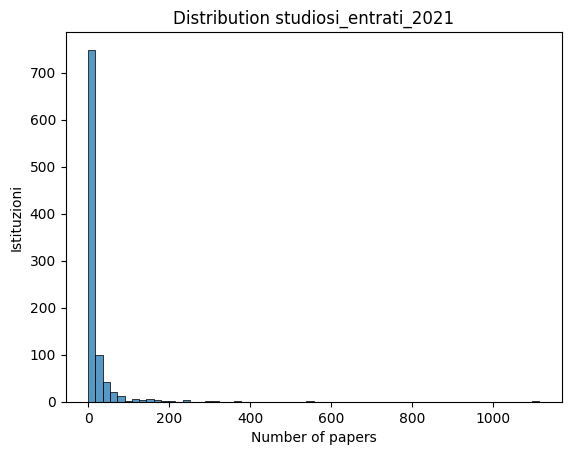

Value counts for studiosi_entrati_2022: 102


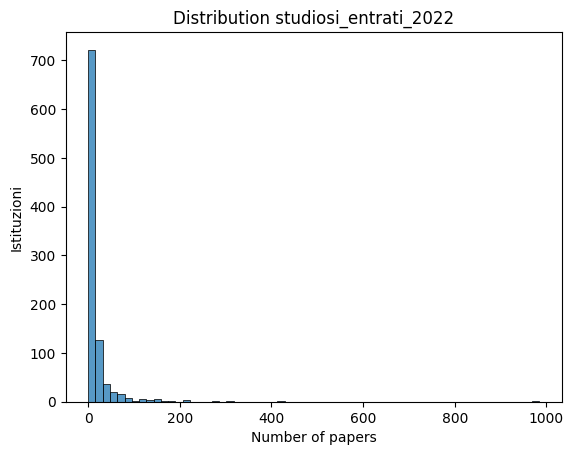

Value counts for studiosi_entrati_2023: 103


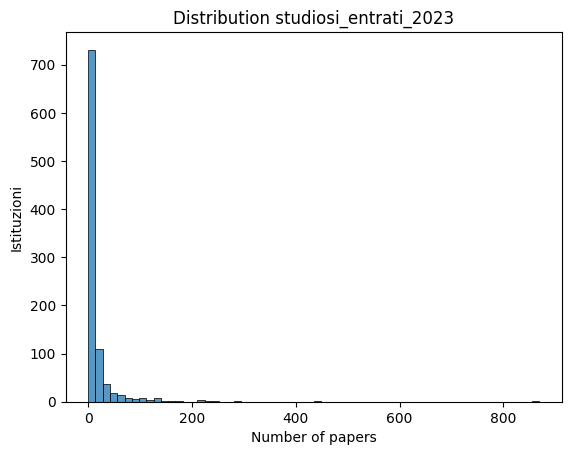

Value counts for studiosi_entrati_2024: 85


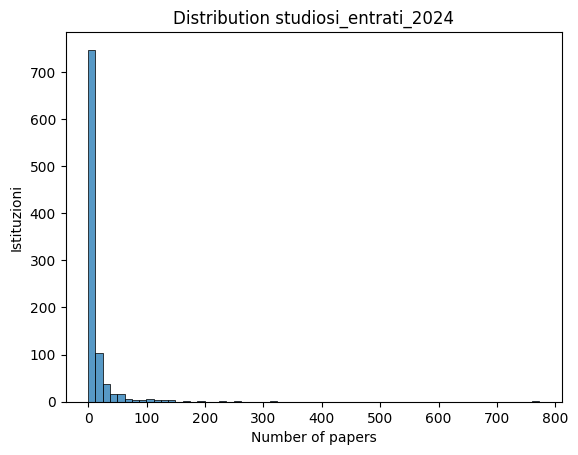

In [115]:
analyze_columns(df, columns_entries)

In [116]:
(df[columns_entries] == 0).any().any()

np.True_

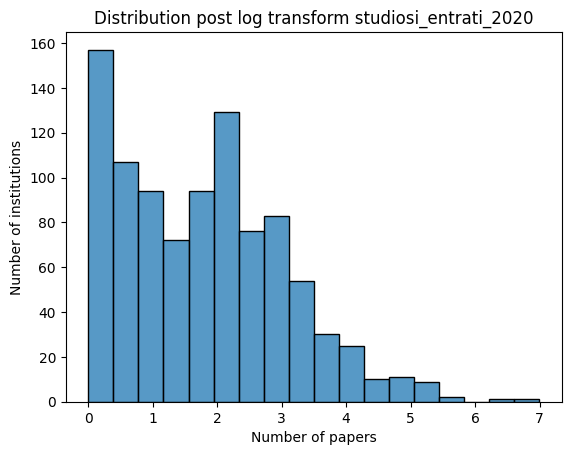

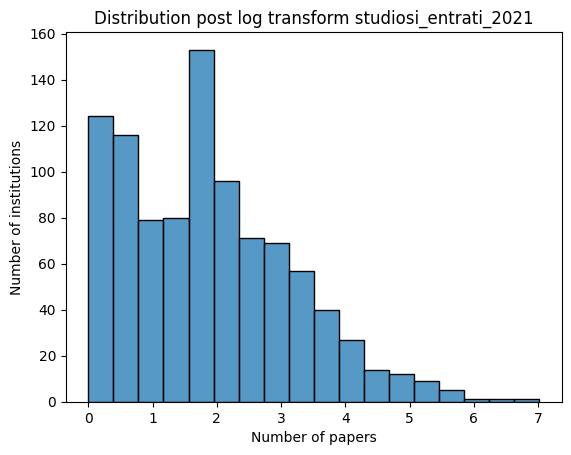

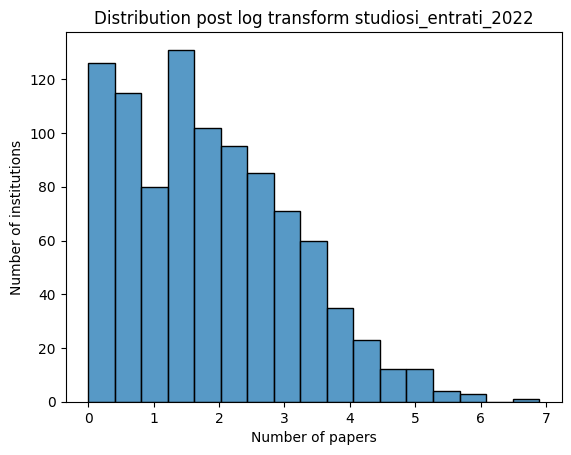

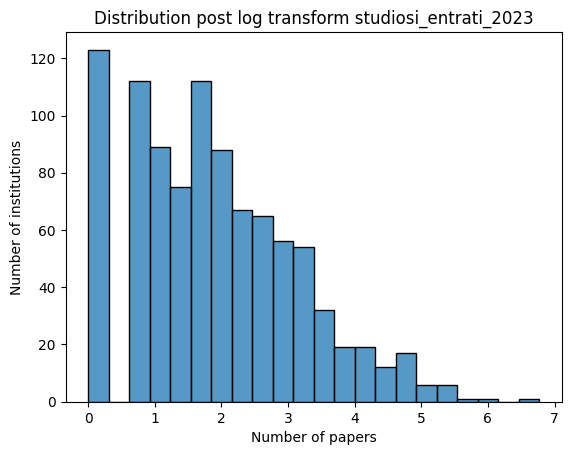

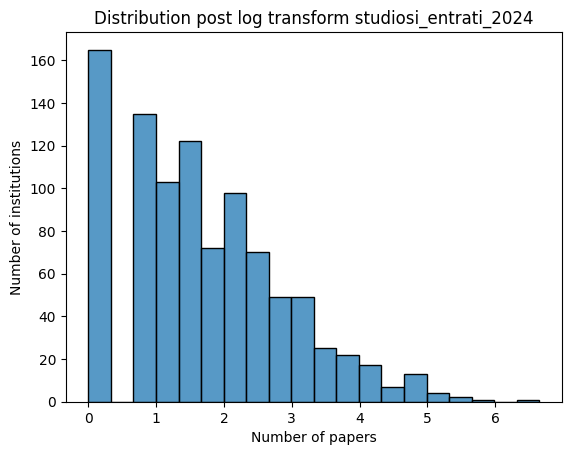

In [117]:
log_transform_works(df, columns_entries)

#### studiosi_usciti

Value counts for studiosi_usciti_2020: 98


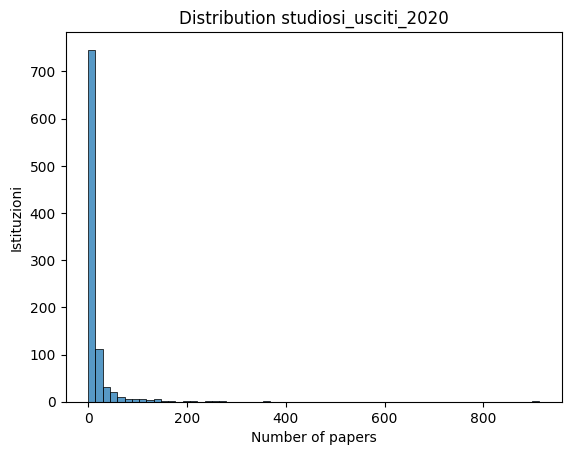

Value counts for studiosi_usciti_2021: 104


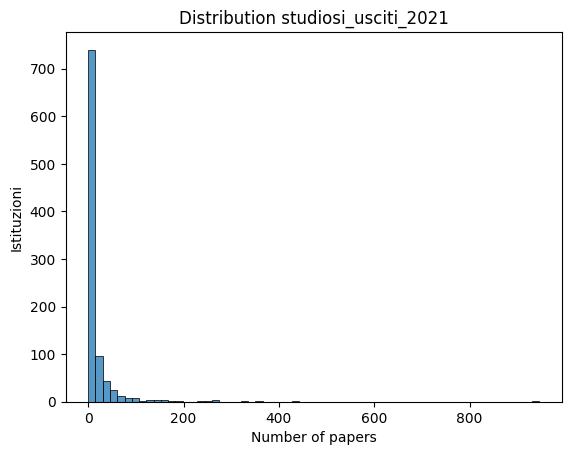

Value counts for studiosi_usciti_2022: 106


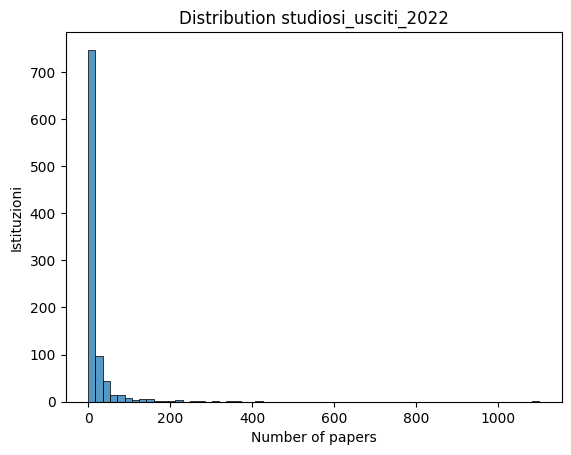

Value counts for studiosi_usciti_2023: 106


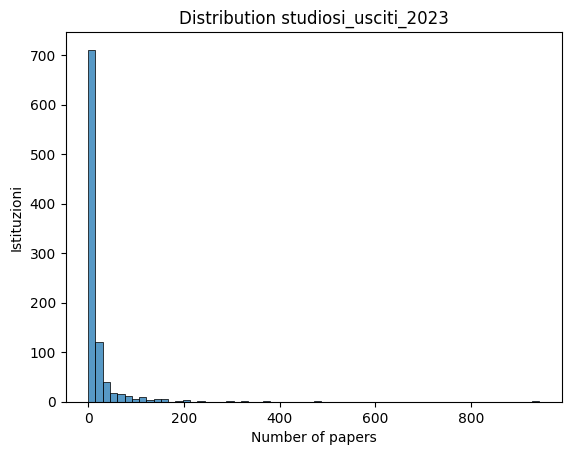

Value counts for studiosi_usciti_2024: 110


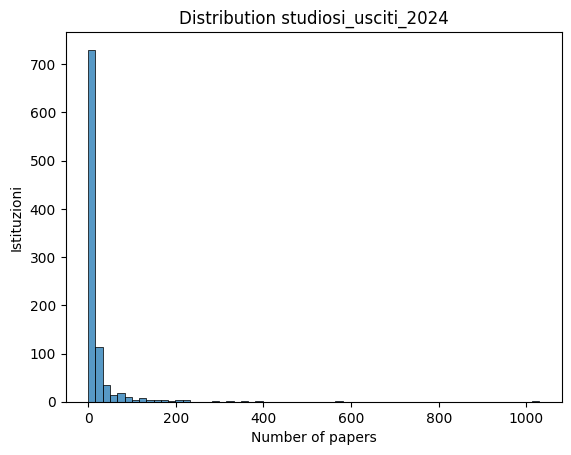

In [118]:
analyze_columns(df, columns_leaving)

In [119]:
(df[columns_leaving] == 0).any().any()

np.True_

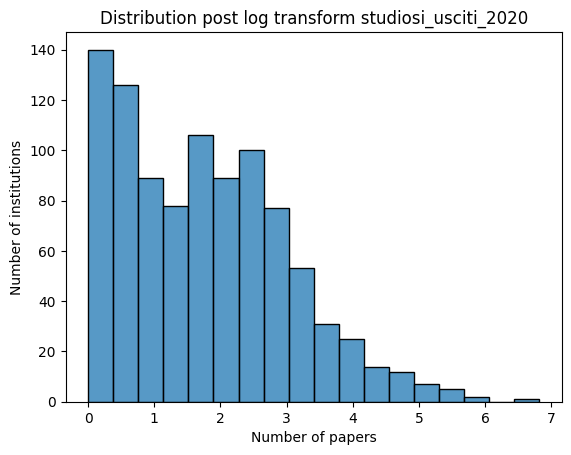

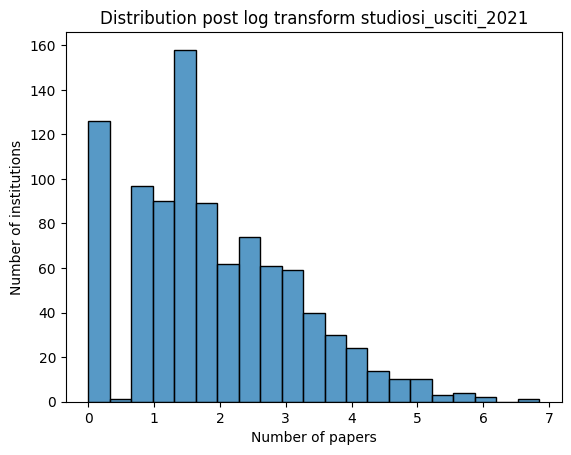

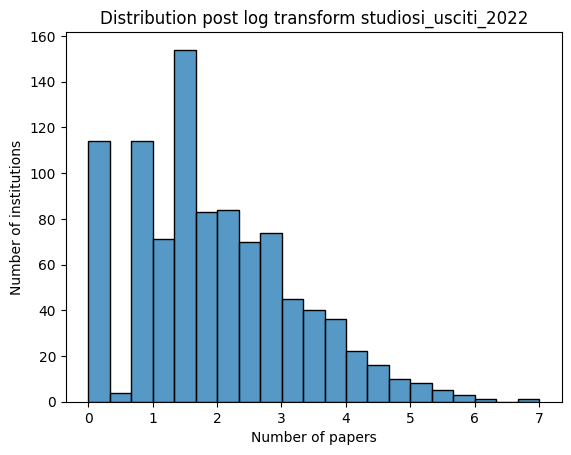

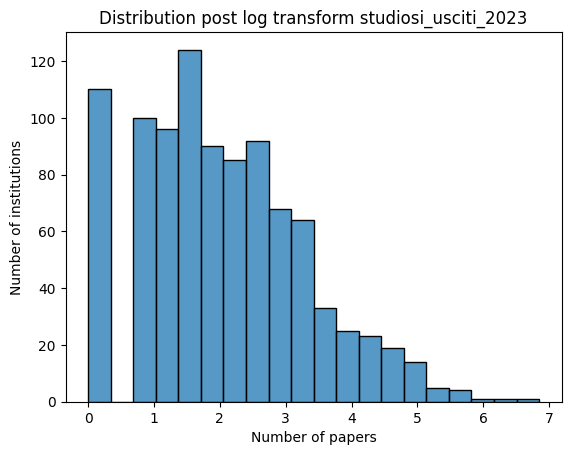

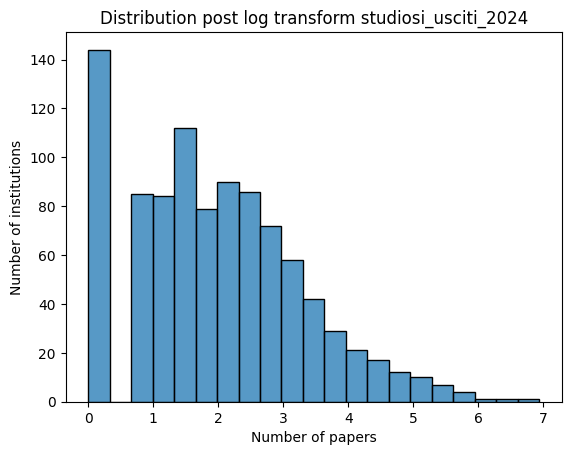

In [120]:
log_transform_works(df, columns_leaving)

### Papers

In [121]:
import re
colonne_papers = [col for col in df.columns if re.match(r'^\d{4}', col)]

Value counts for 2020_Health Sciences: 684


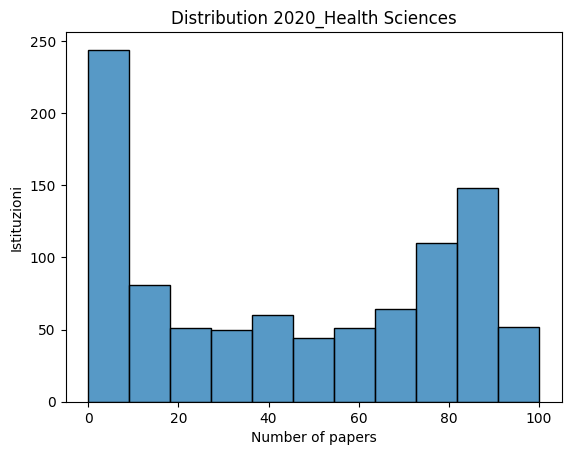

Value counts for 2020_Life Sciences: 604


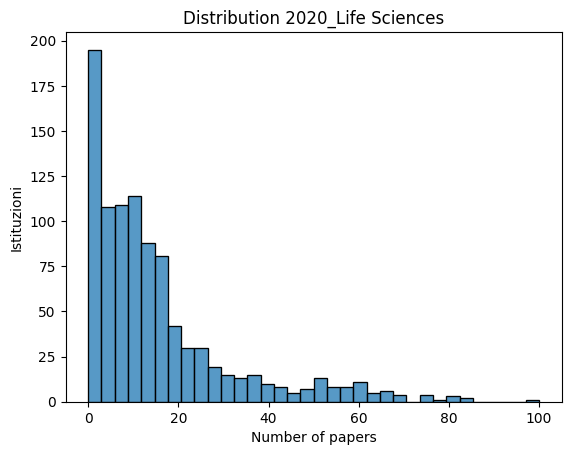

Value counts for 2020_Social Sciences: 503


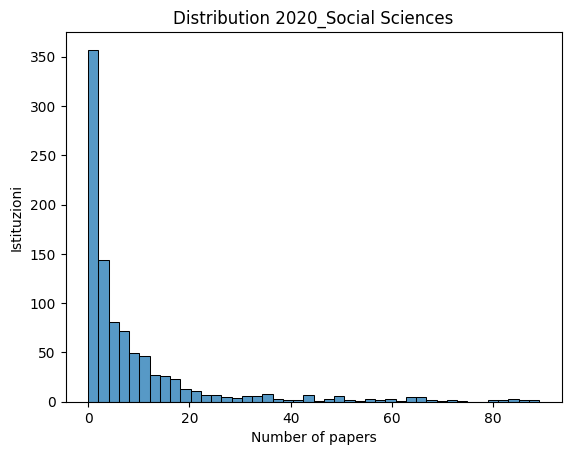

Value counts for 2020_Physical Sciences: 627


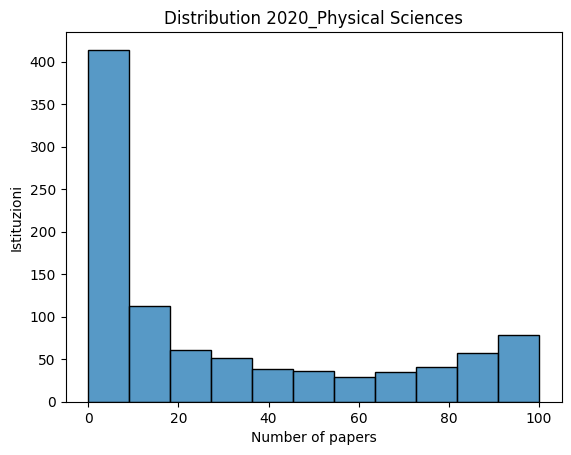

Value counts for 2021_Health Sciences: 671


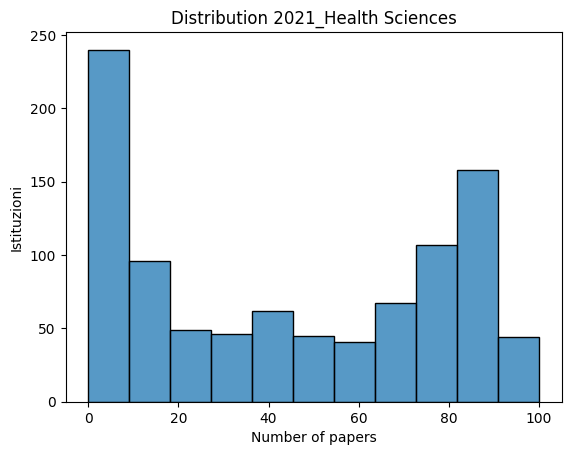

Value counts for 2021_Life Sciences: 600


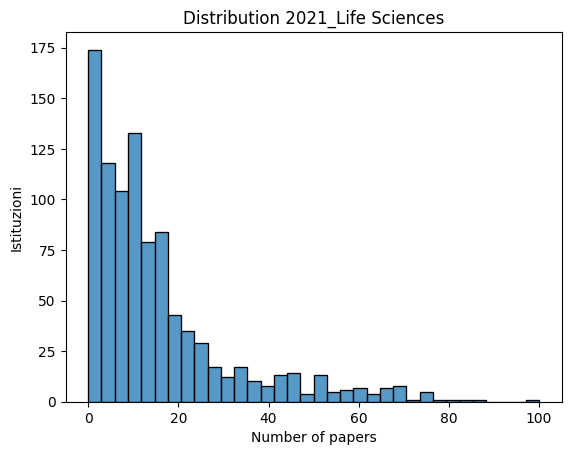

Value counts for 2021_Social Sciences: 523


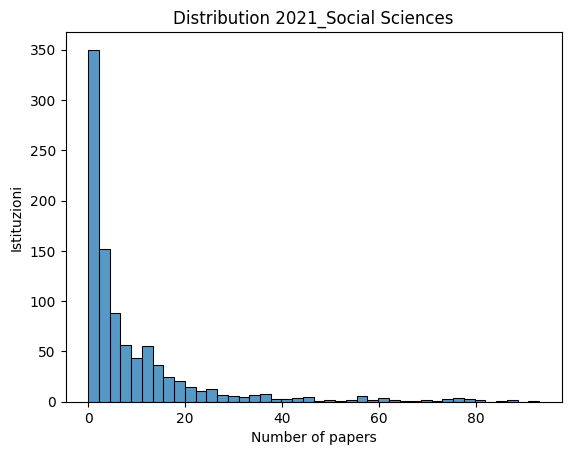

Value counts for 2021_Physical Sciences: 639


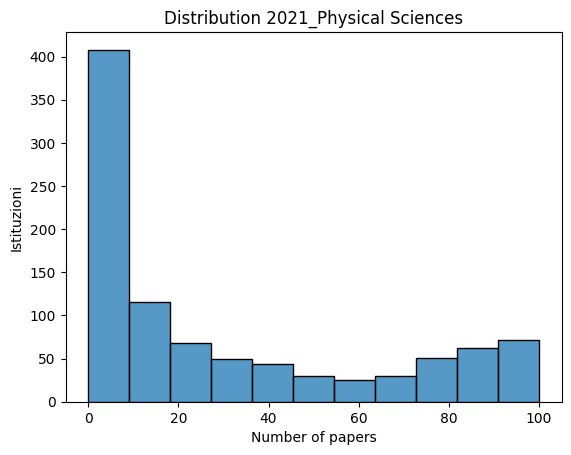

Value counts for 2022_Health Sciences: 693


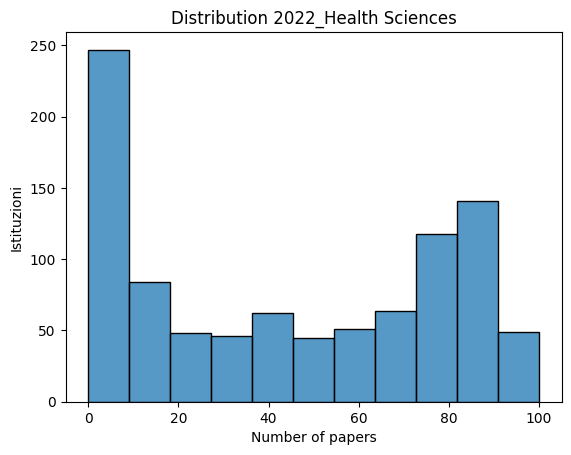

Value counts for 2022_Life Sciences: 592


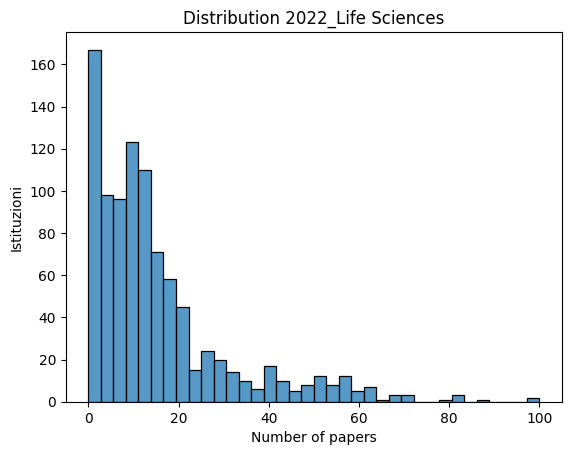

Value counts for 2022_Social Sciences: 529


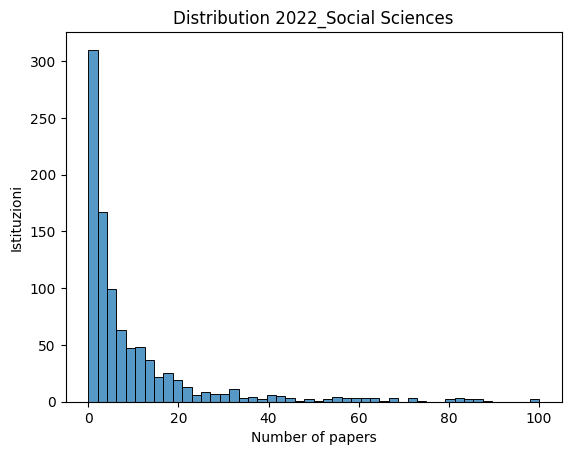

Value counts for 2022_Physical Sciences: 648


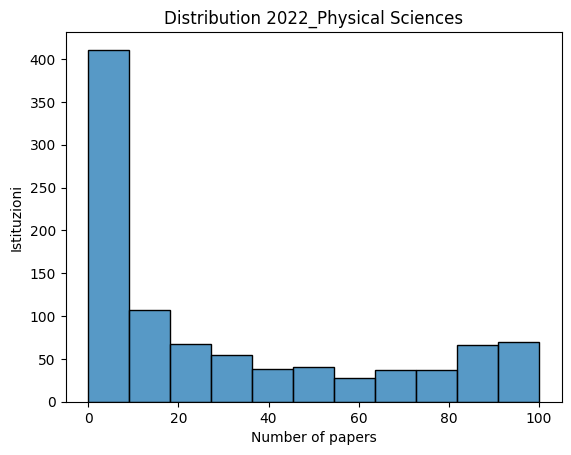

Value counts for 2023_Health Sciences: 683


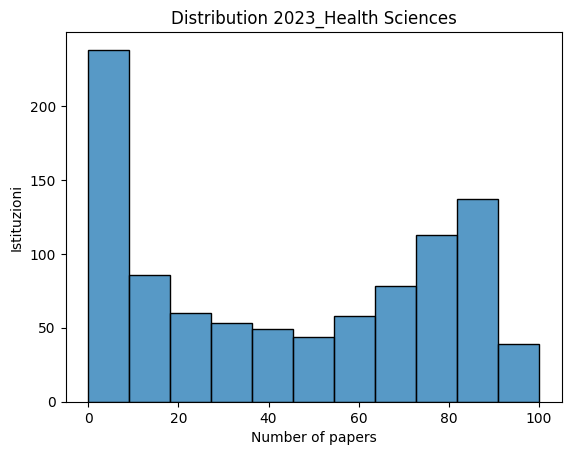

Value counts for 2023_Life Sciences: 605


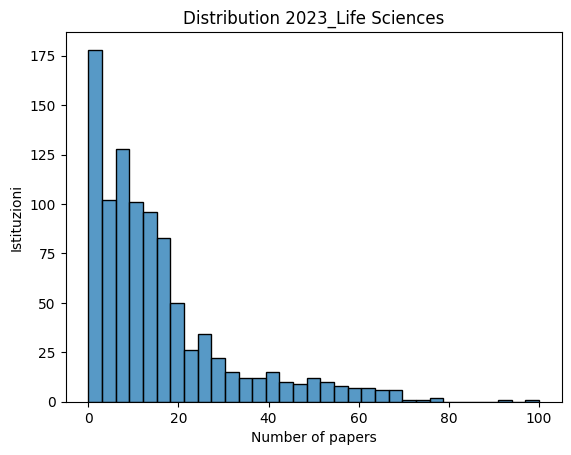

Value counts for 2023_Social Sciences: 524


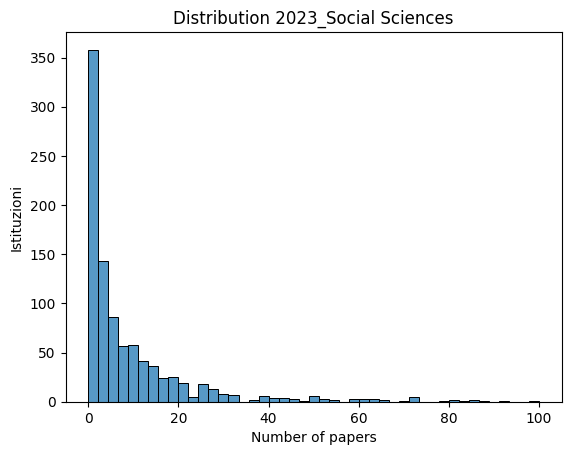

Value counts for 2023_Physical Sciences: 658


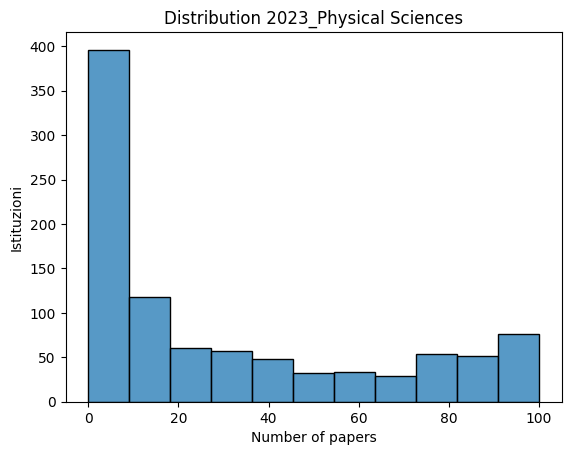

Value counts for 2024_Health Sciences: 680


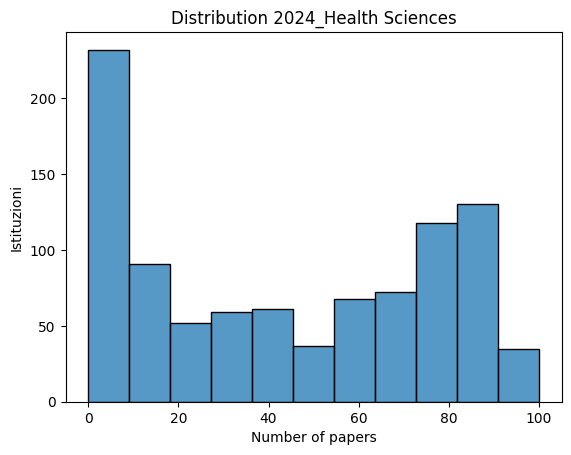

Value counts for 2024_Life Sciences: 596


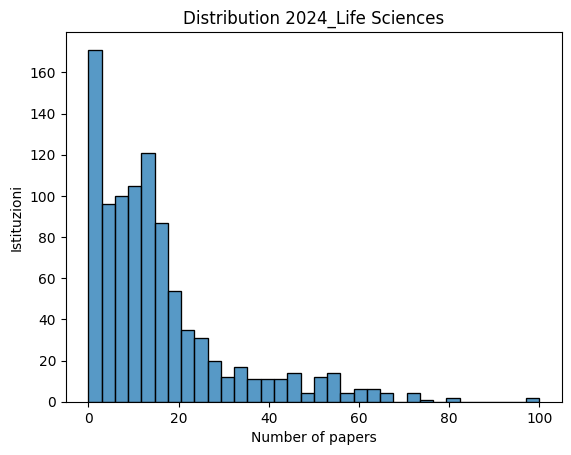

Value counts for 2024_Social Sciences: 510


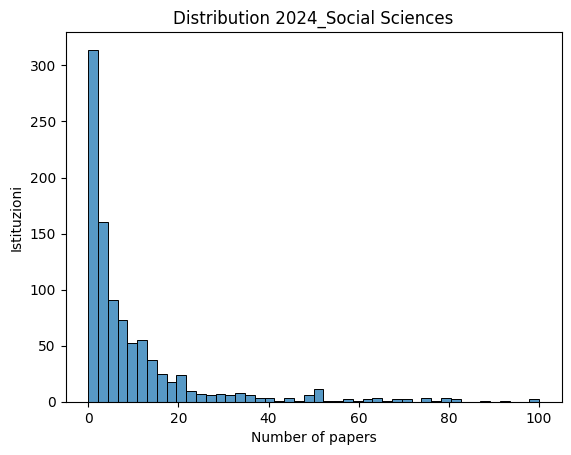

Value counts for 2024_Physical Sciences: 636


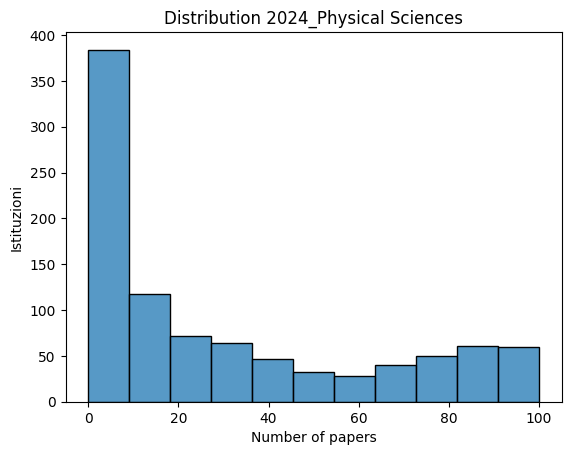

In [122]:
analyze_columns(df, colonne_papers)

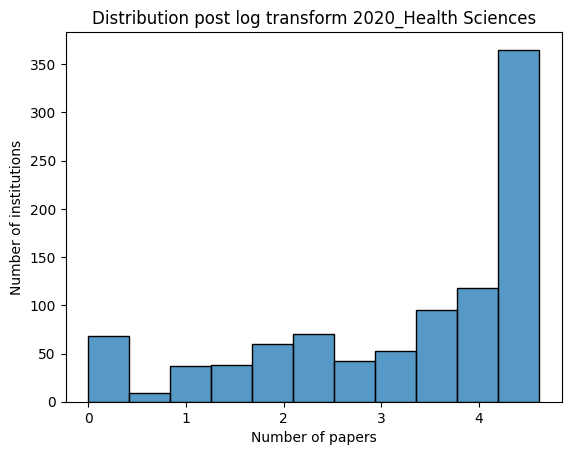

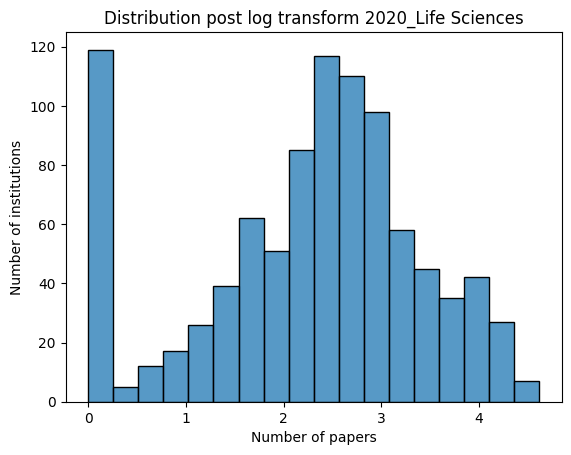

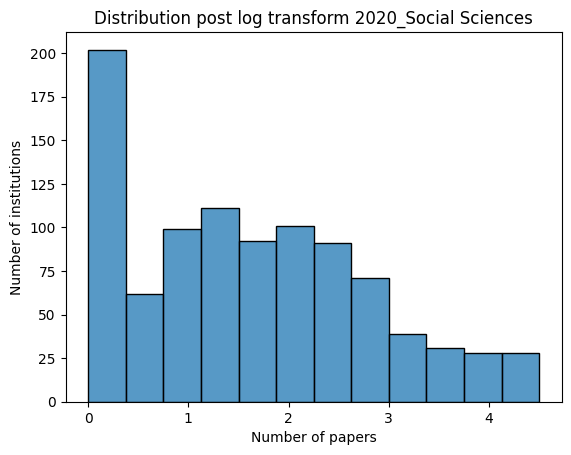

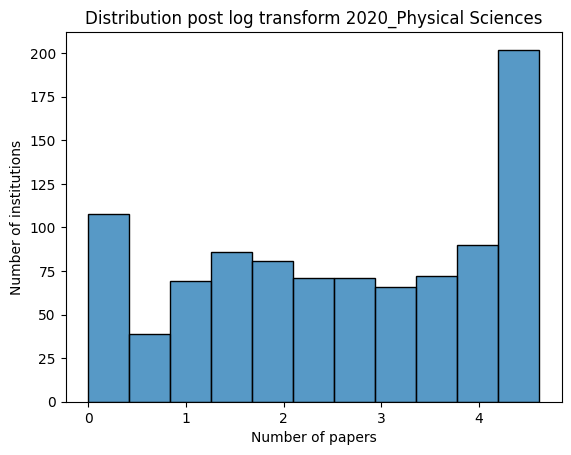

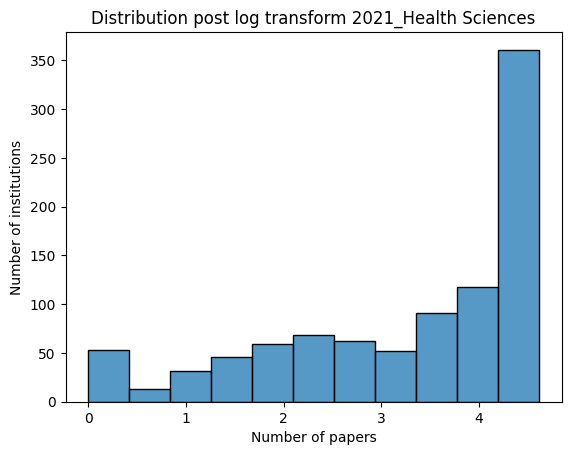

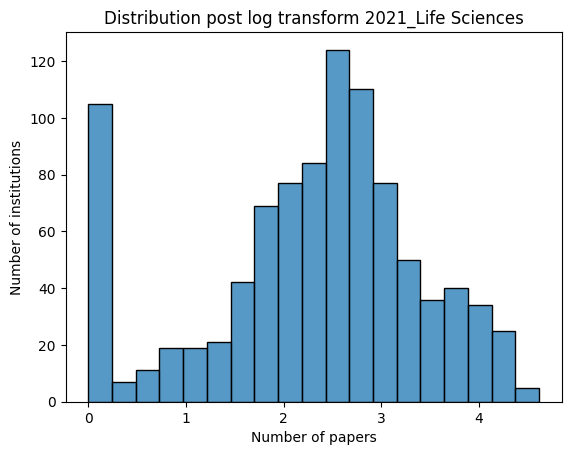

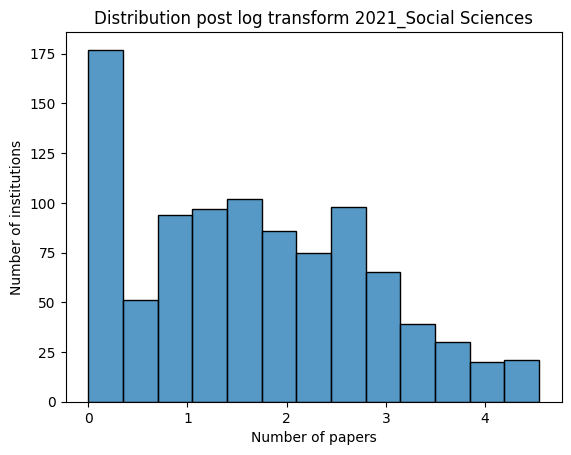

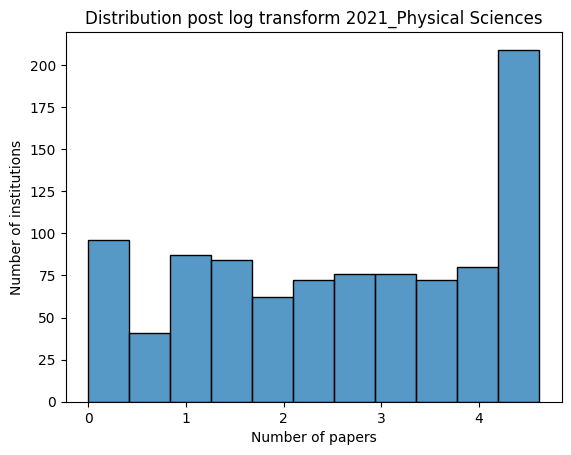

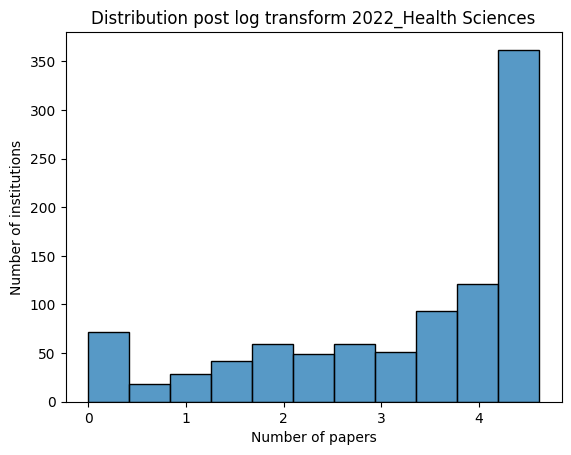

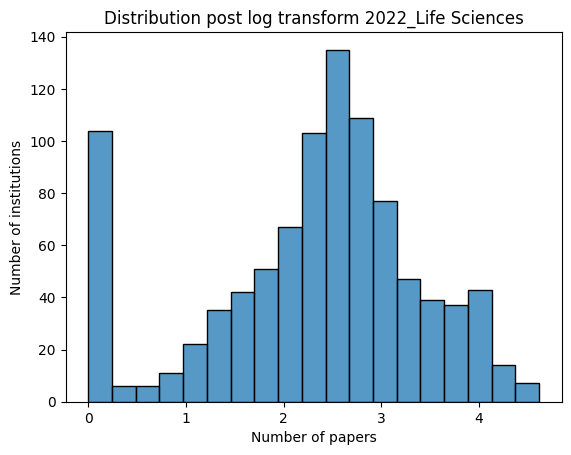

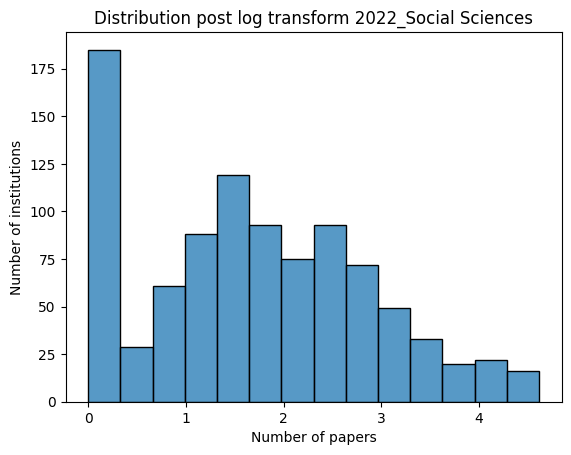

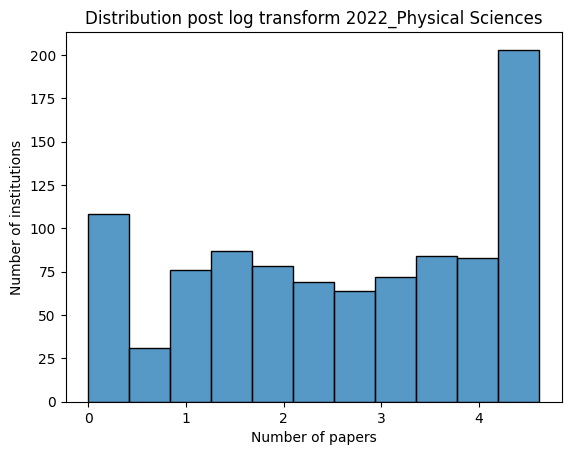

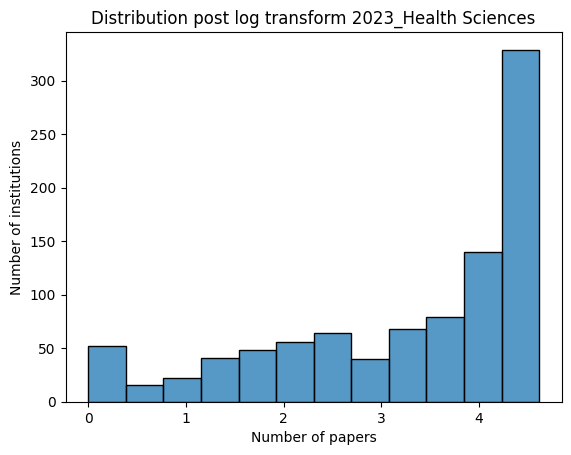

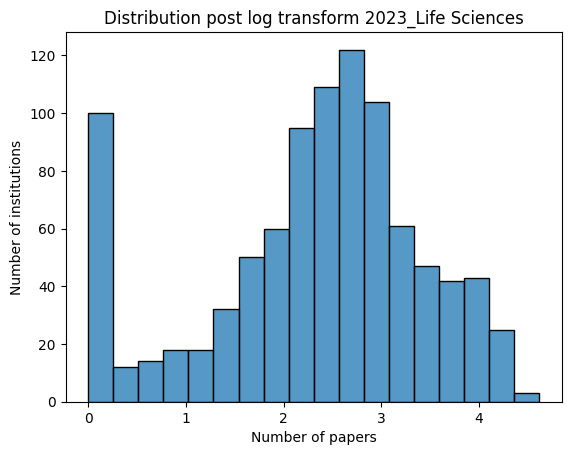

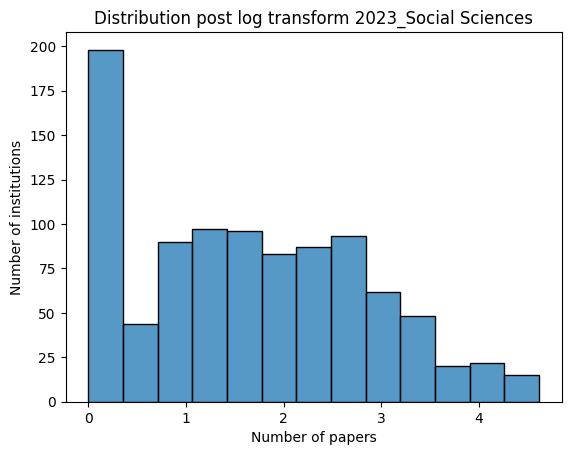

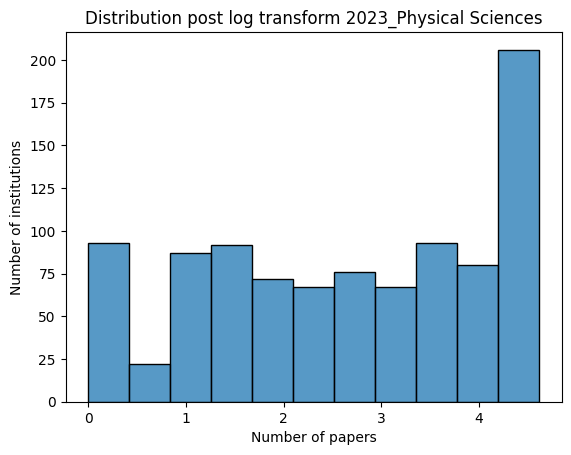

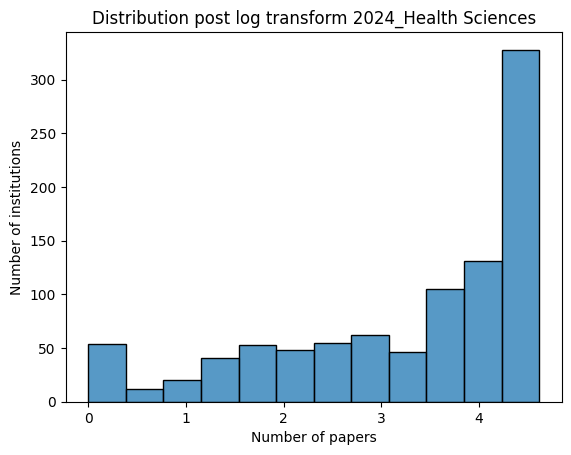

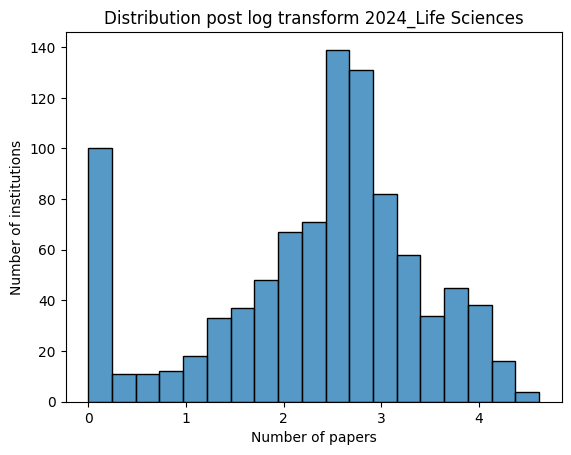

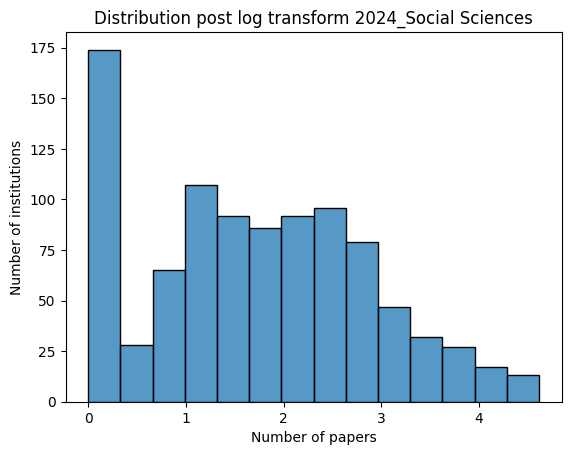

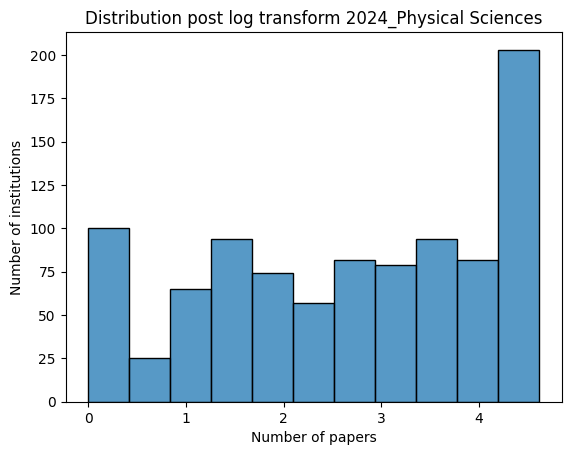

In [123]:
log_transform_works(df, colonne_papers)

## One hot encoding delle classi rimanenti

In [124]:
df.columns

Index(['nome_istituzione', 'city', 'regione', 'macroarea', 'type',
       'works_count_2023', 'cited_by_count_2023', 'works_count_2022',
       'cited_by_count_2022', 'works_count_2021', 'cited_by_count_2021',
       'works_count_2020', 'cited_by_count_2020',
       'tot_dipendenti_per_anno_2020', 'studiosi_usciti_2020',
       'studiosi_entrati_2020', 'tot_dipendenti_per_anno_2021',
       'studiosi_usciti_2021', 'studiosi_entrati_2021',
       'tot_dipendenti_per_anno_2022', 'studiosi_usciti_2022',
       'studiosi_entrati_2022', 'tot_dipendenti_per_anno_2023',
       'studiosi_usciti_2023', 'studiosi_entrati_2023',
       'tot_dipendenti_per_anno_2024', 'studiosi_usciti_2024',
       'studiosi_entrati_2024', '2020_Health Sciences', '2020_Life Sciences',
       '2020_Social Sciences', '2020_Physical Sciences',
       '2021_Health Sciences', '2021_Life Sciences', '2021_Social Sciences',
       '2021_Physical Sciences', '2022_Health Sciences', '2022_Life Sciences',
       '2022_Social 

In [125]:
df_encoded = pd.get_dummies(df, columns = ['regione', 'macroarea', 'type', 'city'])

## Check

In [126]:
df_encoded

,nome_istituzione,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,role_funder,role_institution,role_publisher,regione_Abruzzo,regione_Aosta Valley,regione_Apulia,regione_Basilicate,regione_Calabria,regione_Campania,regione_Emilia-Romagna,regione_Friuli Venezia Giulia,regione_Lazio,regione_Liguria,regione_Lombardy,regione_Molise,regione_Piedmont,regione_Sardinia,regione_Sicily,regione_The Marches,regione_Trentino-Alto Adige,regione_Tuscany,regione_Umbria,regione_Veneto,macroarea_Centro,macroarea_Isole,macroarea_Nord,macroarea_Sud,type_archive,type_company,type_education,type_facility,type_government,type_healthcare,type_nonprofit,type_other,city_Abano Terme,city_Abbiategrasso,city_Acquaviva delle Fonti,city_Agrate Brianza,city_Albano Laziale,city_Alessandria,city_Ancona,city_Andria,city_Aosta,city_Apiro,city_Arezzo,city_Ariano Irpino,city_Arnesano,city_Asti,city_Avellino,city_Aviano,city_Barga,city_Bari,city_Basiglio,city_Bassano del Grappa,city_Benevento,city_Bergamo,city_Biella,city_Bollate,city_Bologna,city_Bolzano,city_Bosisio Parini,city_Bra,city_Brescia,city_Bresso,city_Brindisi,city_Bruneck,city_Buccino,city_Busto Arsizio,city_Buttrio,city_Cagliari,city_Calenzano,city_Camaiore,city_Camerino,city_Campobasso,city_Candiolo,city_Capua,city_Carpi,city_Carrara,city_Casale Monferrato,city_Casalecchio di Reno,city_Casamassima,city_Cascina,city_Caserta,city_Cassino,city_Castel Gandolfo,city_Castelfranco Veneto,city_Castellana Grotte,city_Castellanza,city_Catania,city_Catanzaro,city_Cattolica,city_Cefalù,city_Cernusco sul Naviglio,city_Cesena,city_Chieri,city_Chieti,city_Città Sant'Angelo,city_Città di Castello,city_Civita Castellana,city_Civitanova Marche,city_Cologno Monzese,city_Como,city_Cosenza,city_Cotignola,city_Crema,city_Cremona,city_Crevalcore,city_Crotone,city_Cuneo,city_Desio,city_Empoli,city_Enna,city_Faenza,city_Ferrara,city_Fisciano,city_Florence,city_Foggia,city_Foligno,city_Forlì,city_Formello,city_Francavilla Fontana,city_Frascati,city_Frosinone,city_Garda,city_Genoa,city_Gorizia,city_Gravedona,city_Grosseto,city_Grugliasco,city_Imola,city_Ispra,city_Ivrea,city_La Spezia,city_Lainate,city_Lanciano,city_Latina,city_Lavagna,city_Lecce,city_Lecco,city_Legnaro,city_Livorno,city_Lodi,city_Longastrino,city_Lucca,city_L’Aquila,city_Macerata,city_Maddaloni,city_Mangone,city_Mantova,city_Maranello,city_Marostica,city_Matera,city_Meldola,city_Meran,city_Messina,city_Mestre,city_Milan,city_Mirano,city_Modena,city_Molise,city_Moncalieri,city_Monfalcone,city_Monserrato,city_Monterotondo,city_Monza,city_Mozzagrogna,city_Naples,city_Narni,city_Negrar,city_Nerviano,city_Novara,city_Novedrate,city_Nus,city_Orbassano,city_Oristano,city_Ornavasso,city_Padova,city_Padua,city_Palermo,city_Parabiago,city_Parma,city_Pavia,city_Pavullo nel Frignano,city_Perugia,city_Pesaro,city_Pescara,city_Piacenza,city_Pietra Ligure,city_Pinerolo,city_Pino Torinese,city_Pisa,city_Pistoia,city_Pomezia,city_Pontecagnano,city_Pontedera,city_Porcia,city_Pordenone,city_Portici,city_Potenza,city_Povo,city_Pozzilli,city_Pozzuoli,city_Prato,city_Pula,city_Ragusa,city_Ravenna,city_Reggio Calabria,

In [127]:
df_encoded = df_encoded.loc[:, ~df_encoded.columns.str.contains(r'2019')]

In [128]:
df_encoded = df_encoded.drop('nome_istituzione', axis = 1)

In [129]:
# # One hot Encoding
# from sklearn.preprocessing import MultiLabelBinarizer

# mlb = MultiLabelBinarizer()
# roles_encoded = mlb.fit_transform(df['roles'])

# column_names = [f'role_{role}' for role in mlb.classes_]
# df_roles_encoded = pd.DataFrame(roles_encoded, columns = column_names, index=df.index)

# # Inseriamo le nuove colonne in df e poi droppiamo le vecchie
# df = pd.concat([df, df_roles_encoded], axis = 1)
# df.drop(columns = ['roles'], inplace=True)

## Creazione dataframe di training e di testing

In [130]:
df_encoded

,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,role_funder,role_institution,role_publisher,regione_Abruzzo,regione_Aosta Valley,regione_Apulia,regione_Basilicate,regione_Calabria,regione_Campania,regione_Emilia-Romagna,regione_Friuli Venezia Giulia,regione_Lazio,regione_Liguria,regione_Lombardy,regione_Molise,regione_Piedmont,regione_Sardinia,regione_Sicily,regione_The Marches,regione_Trentino-Alto Adige,regione_Tuscany,regione_Umbria,regione_Veneto,macroarea_Centro,macroarea_Isole,macroarea_Nord,macroarea_Sud,type_archive,type_company,type_education,type_facility,type_government,type_healthcare,type_nonprofit,type_other,city_Abano Terme,city_Abbiategrasso,city_Acquaviva delle Fonti,city_Agrate Brianza,city_Albano Laziale,city_Alessandria,city_Ancona,city_Andria,city_Aosta,city_Apiro,city_Arezzo,city_Ariano Irpino,city_Arnesano,city_Asti,city_Avellino,city_Aviano,city_Barga,city_Bari,city_Basiglio,city_Bassano del Grappa,city_Benevento,city_Bergamo,city_Biella,city_Bollate,city_Bologna,city_Bolzano,city_Bosisio Parini,city_Bra,city_Brescia,city_Bresso,city_Brindisi,city_Bruneck,city_Buccino,city_Busto Arsizio,city_Buttrio,city_Cagliari,city_Calenzano,city_Camaiore,city_Camerino,city_Campobasso,city_Candiolo,city_Capua,city_Carpi,city_Carrara,city_Casale Monferrato,city_Casalecchio di Reno,city_Casamassima,city_Cascina,city_Caserta,city_Cassino,city_Castel Gandolfo,city_Castelfranco Veneto,city_Castellana Grotte,city_Castellanza,city_Catania,city_Catanzaro,city_Cattolica,city_Cefalù,city_Cernusco sul Naviglio,city_Cesena,city_Chieri,city_Chieti,city_Città Sant'Angelo,city_Città di Castello,city_Civita Castellana,city_Civitanova Marche,city_Cologno Monzese,city_Como,city_Cosenza,city_Cotignola,city_Crema,city_Cremona,city_Crevalcore,city_Crotone,city_Cuneo,city_Desio,city_Empoli,city_Enna,city_Faenza,city_Ferrara,city_Fisciano,city_Florence,city_Foggia,city_Foligno,city_Forlì,city_Formello,city_Francavilla Fontana,city_Frascati,city_Frosinone,city_Garda,city_Genoa,city_Gorizia,city_Gravedona,city_Grosseto,city_Grugliasco,city_Imola,city_Ispra,city_Ivrea,city_La Spezia,city_Lainate,city_Lanciano,city_Latina,city_Lavagna,city_Lecce,city_Lecco,city_Legnaro,city_Livorno,city_Lodi,city_Longastrino,city_Lucca,city_L’Aquila,city_Macerata,city_Maddaloni,city_Mangone,city_Mantova,city_Maranello,city_Marostica,city_Matera,city_Meldola,city_Meran,city_Messina,city_Mestre,city_Milan,city_Mirano,city_Modena,city_Molise,city_Moncalieri,city_Monfalcone,city_Monserrato,city_Monterotondo,city_Monza,city_Mozzagrogna,city_Naples,city_Narni,city_Negrar,city_Nerviano,city_Novara,city_Novedrate,city_Nus,city_Orbassano,city_Oristano,city_Ornavasso,city_Padova,city_Padua,city_Palermo,city_Parabiago,city_Parma,city_Pavia,city_Pavullo nel Frignano,city_Perugia,city_Pesaro,city_Pescara,city_Piacenza,city_Pietra Ligure,city_Pinerolo,city_Pino Torinese,city_Pisa,city_Pistoia,city_Pomezia,city_Pontecagnano,city_Pontedera,city_Porcia,city_Pordenone,city_Portici,city_Potenza,city_Povo,city_Pozzilli,city_Pozzuoli,city_Prato,city_Pula,city_Ragusa,city_Ravenna,city_Reggio Calabria,city_Reggio Emili

In [131]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(
    df_encoded,
    test_size=0.4,
    random_state=42,
    #stratify=df_encoded['flow_direction']
)

In [132]:
# Flusso netto solo 2024
train_df['net_flow_2024'] = train_df['studiosi_entrati_2024'] - train_df['studiosi_usciti_2024']
test_df['net_flow_2024'] = test_df['studiosi_entrati_2024'] - test_df['studiosi_usciti_2024']

# Normalizza per la size del 2023 (baseline prima dei cambiamenti)
train_df['net_flow_rate_2024'] = train_df['net_flow_2024'] / train_df['tot_dipendenti_per_anno_2023']
test_df['net_flow_rate_2024'] = test_df['net_flow_2024'] / test_df['tot_dipendenti_per_anno_2023']

In [133]:
# cols_to_drop = []

# for col in train_df.columns:
#     if any(str(y) in col for y in range(2020, 2024)):
#         cols_to_drop.append(col)

# train_df = train_df.drop(columns=cols_to_drop)

In [134]:
# for col in test_df.columns:
#     if any(str(y) in col for y in range(2020, 2024)):
#         cols_to_drop.append(col)

# test_df = test_df.drop(columns=cols_to_drop)

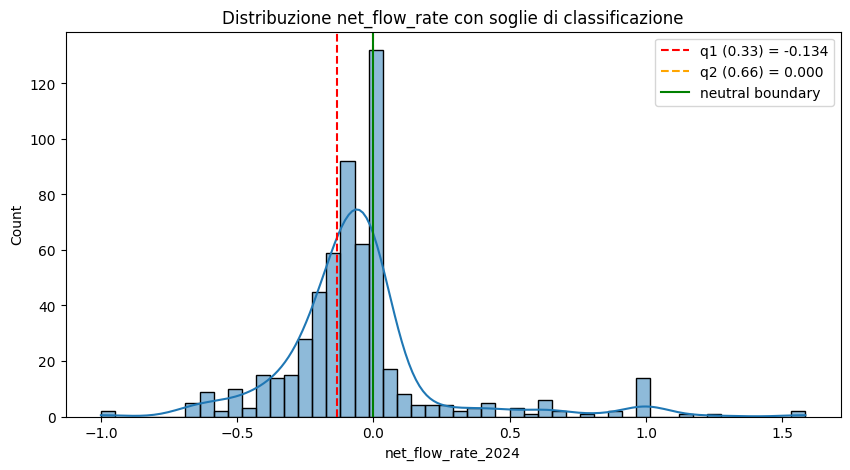

In [135]:
# Calcola i quantili sul training set (60% dei dati, stesso random_state)
train_idx = train_df.sample(frac=0.6, random_state=42).index
q1 = train_df['net_flow_rate_2024'].quantile(0.33)
q2 = train_df['net_flow_rate_2024'].quantile(0.66)

# Visualizzazione
plt.figure(figsize=(10, 5))
sns.histplot(train_df['net_flow_rate_2024'], bins=50, kde=True)
plt.axvline(q1, color='red', linestyle='--', label=f'q1 (0.33) = {q1:.3f}')
plt.axvline(q2, color='orange', linestyle='--', label=f'q2 (0.66) = {q2:.3f}')
plt.axvline(0, color='green', linestyle='-', label='neutral boundary')
plt.legend()
plt.title('Distribuzione net_flow_rate con soglie di classificazione')
plt.show()


Soglia -0.2 / +0.2:
net_flow_rate_2024
stable     407
outflow    116
inflow      50
Name: count, dtype: int64
Rapporto max/min: 8.14

Soglia -0.1 / +0.1:
net_flow_rate_2024
stable     271
outflow    242
inflow      60
Name: count, dtype: int64
Rapporto max/min: 4.52

Soglia -0.15 / +0.15:
net_flow_rate_2024
stable     353
outflow    168
inflow      52
Name: count, dtype: int64
Rapporto max/min: 6.79

Soglia -0.2 / +0.15:
net_flow_rate_2024
stable     405
outflow    116
inflow      52
Name: count, dtype: int64
Rapporto max/min: 7.79

Soglia -0.15 / +0.1:
net_flow_rate_2024
stable     345
outflow    168
inflow      60
Name: count, dtype: int64
Rapporto max/min: 5.75

Soglia -0.1342817305428085 / +0.0:
net_flow_rate_2024
stable     301
outflow    189
inflow      83
Name: count, dtype: int64
Rapporto max/min: 3.63


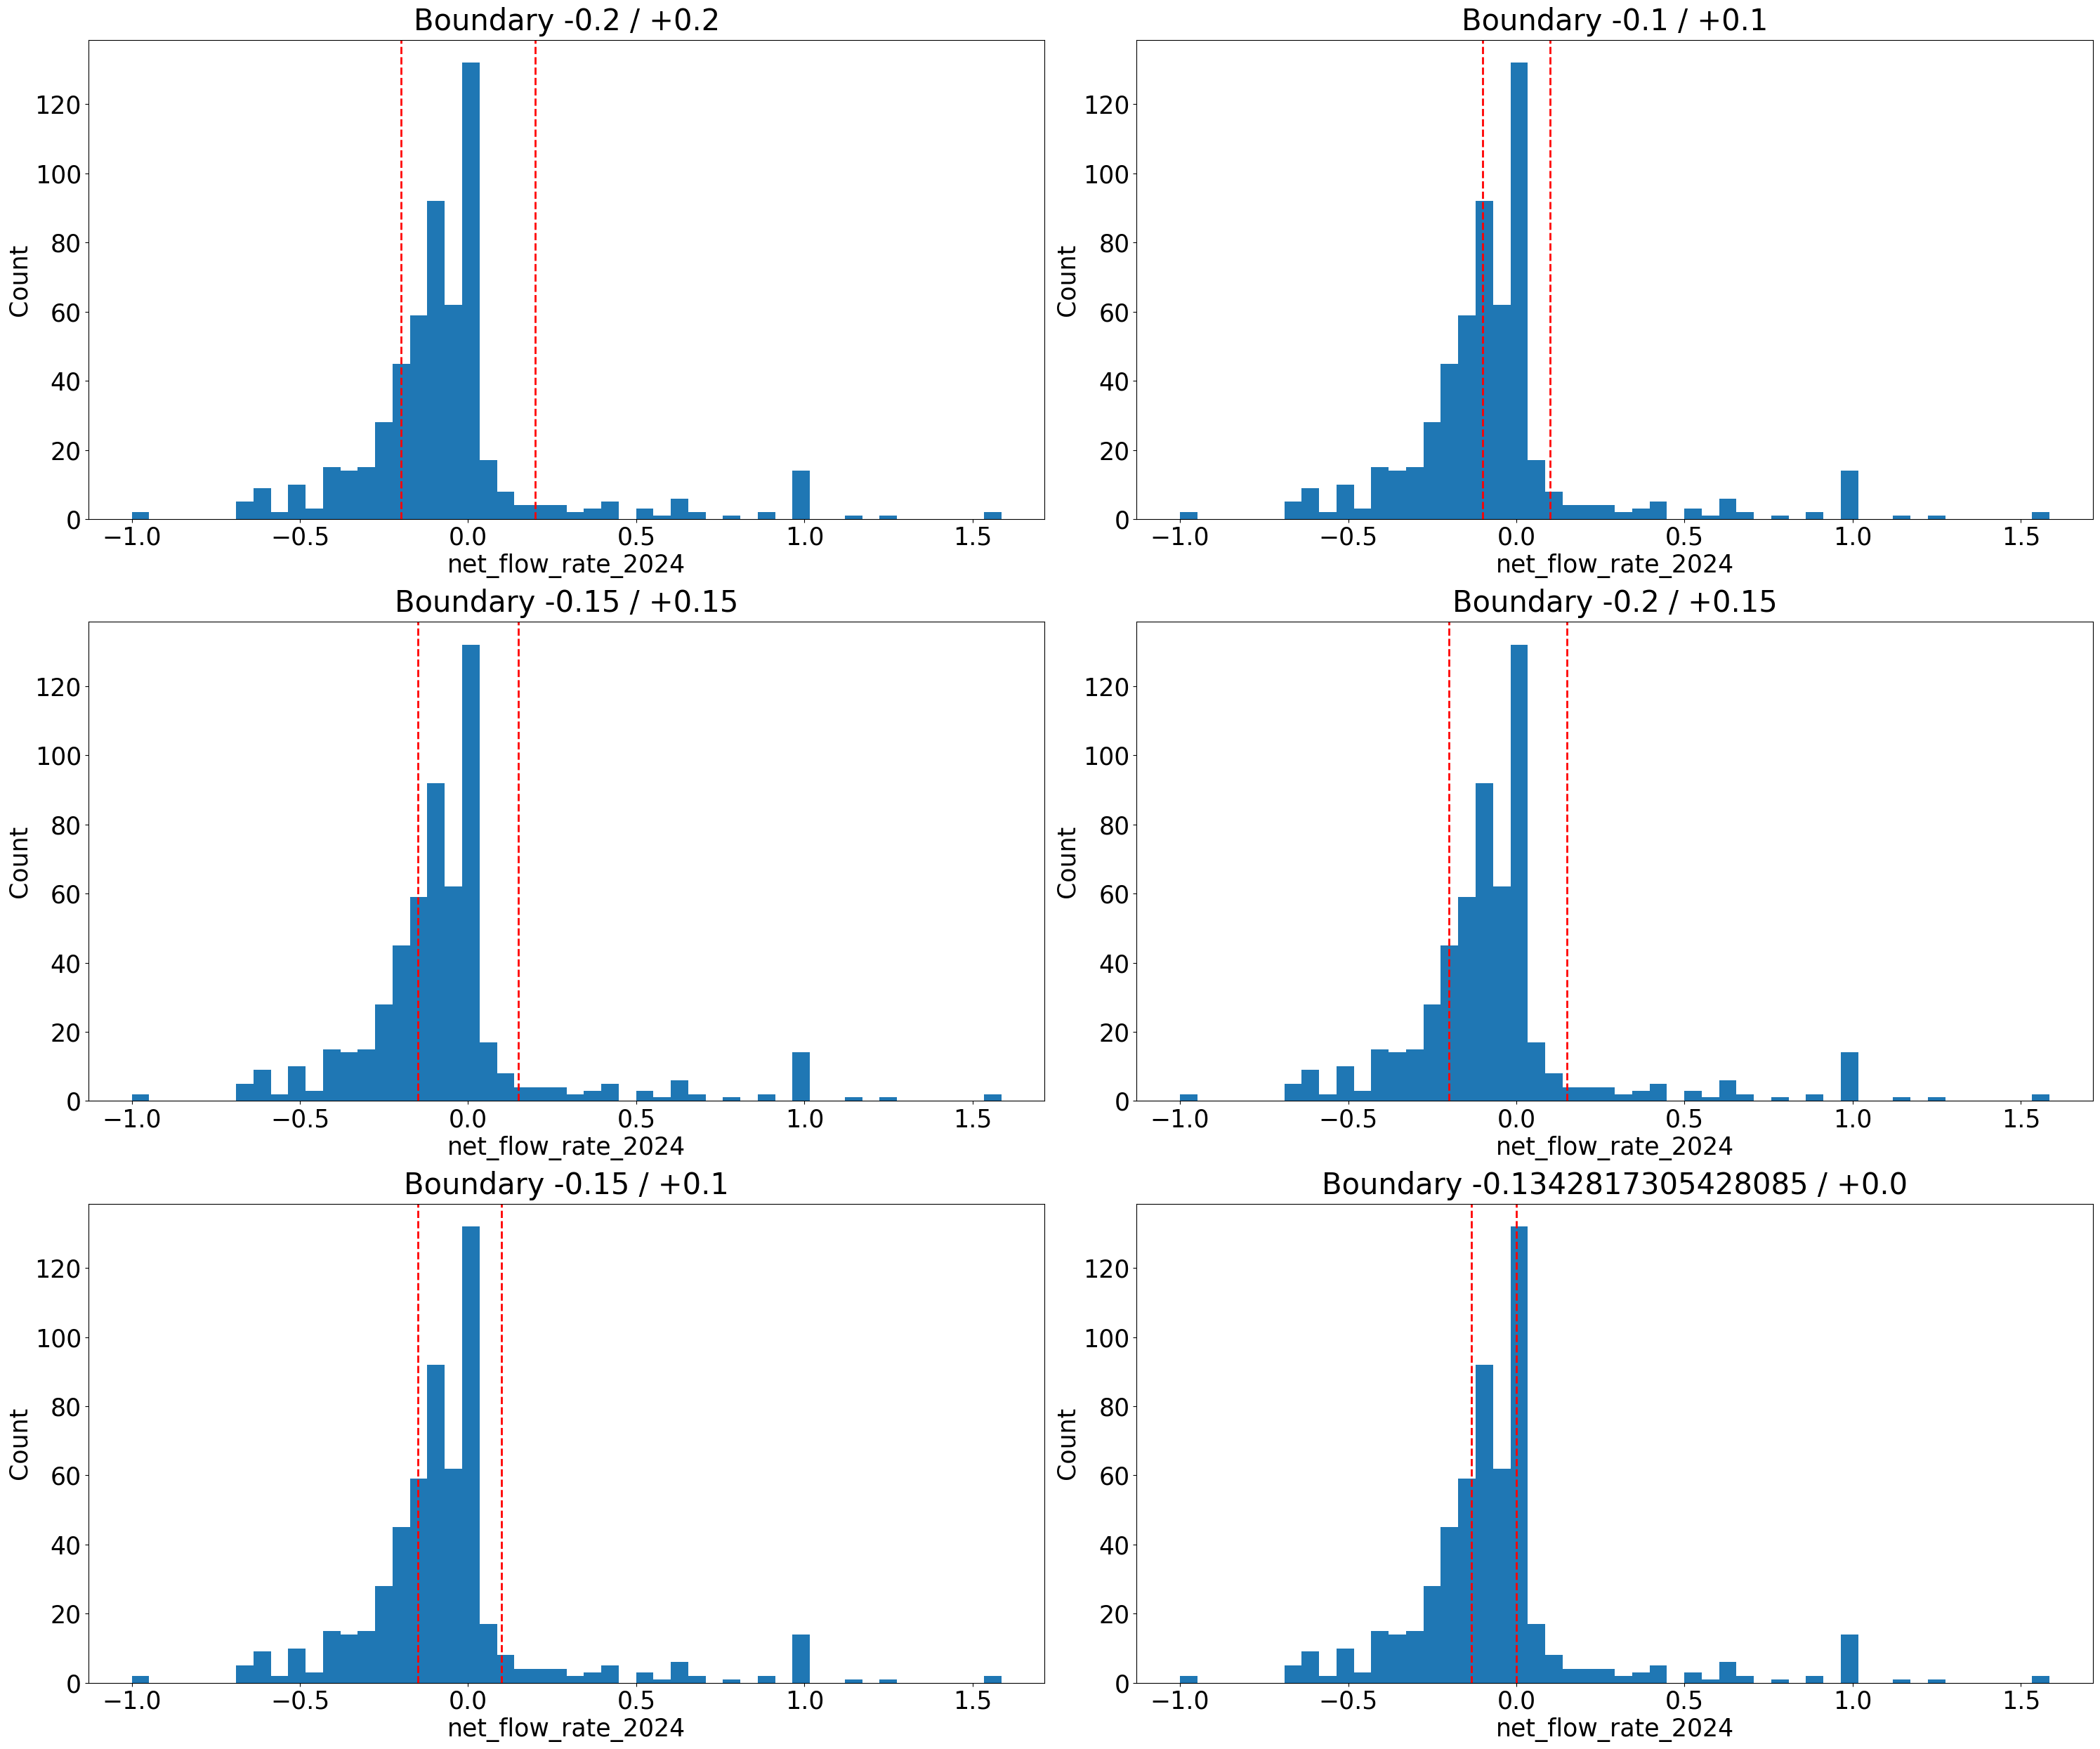

In [137]:
soglie_asimmetriche = [(-0.20, 0.20), (-0.10, 0.10), (-0.15, 0.15), (-0.20, 0.15), (-0.15, 0.10), (q1, q2)]

for soglia_neg, soglia_pos in soglie_asimmetriche:
    classi = pd.cut(train_df['net_flow_rate_2024'],
                    bins=[-np.inf, soglia_neg, soglia_pos, np.inf],
                    labels=['outflow', 'stable', 'inflow'])
    print(f"\nSoglia {soglia_neg} / +{soglia_pos}:")
    print(classi.value_counts())
    print(f"Rapporto max/min: {classi.value_counts().max() / classi.value_counts().min():.2f}")

fig, axes = plt.subplots(3, 2, figsize=(30, 25))
axes = axes.flatten()

for i, (soglia_neg, soglia_pos) in enumerate(soglie_asimmetriche):
    axes[i].hist(train_df['net_flow_rate_2024'], bins=50)
    axes[i].axvline(soglia_pos, color='red', linestyle='--', linewidth=2)
    axes[i].axvline(soglia_neg, color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'Boundary {soglia_neg} / +{soglia_pos}', fontsize=30, pad=10)
    axes[i].set_xlabel('net_flow_rate_2024', fontsize=25)
    axes[i].set_ylabel('Count', fontsize=25)
    axes[i].tick_params(axis='both', labelsize=25)

plt.tight_layout()
plt.show()

In [91]:
# def classify_flow(rate):
#     if rate > 0.10:
#         return 'inflow'
#     elif rate < -0.15:
#         return 'outflow'
#     else:
#         return 'stable'

# Calcola i quantili SOLO sul training set
# q33 = train_df['net_flow_rate_2024'].quantile(0.33)
# q66 = train_df['net_flow_rate_2024'].quantile(0.66)

q33 = -0.20
q66 = 0.10

# Adatta la funzione con le soglie fisse
def classify_flow(rate):
    if rate > q66:
        return 'inflow'
    elif rate < q33:
        return 'outflow'
    else:
        return 'stable'

# Applica ad entrambi usando le stesse soglie
train_df['flow_direction'] = train_df['net_flow_rate_2024'].apply(classify_flow)
test_df['flow_direction'] = test_df['net_flow_rate_2024'].apply(classify_flow)

# Pulizia
train_df = train_df.drop(['net_flow_2024', 'net_flow_rate_2024'], axis=1)
test_df = test_df.drop(['net_flow_2024', 'net_flow_rate_2024'], axis=1)

In [92]:
# Dopo la split
train_df['target'] = train_df['flow_direction']
test_df['target'] = test_df['flow_direction']

train_df = train_df.drop(['flow_direction'], axis=1)
test_df = test_df.drop(['flow_direction'], axis=1)


In [93]:
# Label Encoding della variabile target
from sklearn.preprocessing import LabelEncoder
lab_encoder = LabelEncoder()
train_df['target'] = lab_encoder.fit_transform(train_df['target'])
test_df['target'] = lab_encoder.transform(test_df['target'])

In [94]:
lab_encoder.classes_

array(['inflow', 'outflow', 'stable'], dtype=object)

In [95]:
cols_2024 = df_encoded.filter(regex=r'2024').columns
print(cols_2024)

train_df = train_df.drop(cols_2024, axis=1)
test_df = test_df.drop(cols_2024, axis=1)

Index(['tot_dipendenti_per_anno_2024', 'studiosi_usciti_2024',
       'studiosi_entrati_2024', '2024_Health Sciences', '2024_Life Sciences',
       '2024_Social Sciences', '2024_Physical Sciences'],
      dtype='object')


In [96]:
import joblib
joblib.dump(lab_encoder, 'label_encoder.pkl')

['label_encoder.pkl']

In [97]:
train_df.to_csv('df_train.csv', index=False)
test_df.to_csv('df_test.csv', index = False)